# 08_B3_LamaHCEExt_Train_P05S05_Seed111

Bản nguồn chờ Save & Run All trên Kaggle; chưa có output thực nghiệm.

B3 P05S05 - che theo nguồn khi train, p_step=0.05, p_sequence=0.05, seed 111.
GPU T4, Internet On. Gắn đủ ba Input dưới đây bằng Add Input trên Kaggle:
1. Dataset hunhngcthng/lamah-ce-ext.
2. Output 01_B2_LamaHCEExt_DataLoader - bản T4 đạt 57 + 4 ca, cùng Output đã dùng cho B2.
3. Output 06_B2_LamaHCEExt_Train_Seed111 - Version 1.
Gắn nguyên Output notebook nguồn; mã tự đọc các tệp từ manifest.
Output run này: /kaggle/working/b3_output, /kaggle/working/b3_runs, /kaggle/working/b3_configs.
Mục lục: 1 môi trường; 2 config B2; 3 dựng Q; 4 config/mẫu/scaler/probe che; 5 train; 6 checkpoint/test; 7 hình; 8 manifest.

## Phần 1 - Cài thư viện NeuralHydrology từ fork của nhóm, kiểm môi trường

In [1]:
# Dùng commit B2 đã kiểm; B3 chỉ đổi cấu hình che; kiểm T4 đã Save trước khi cài và chạy.
import importlib
import importlib.metadata as md
import json
import hashlib
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "2ccaa147a6ec87d0f56fa3e2f11b1bf38079253f"   # Cùng commit B2, không đổi mã thư viện
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "numba", "ruamel.yaml", "matplotlib", "tensorboard", "tqdm"]
NH_MODULES = ["neuralhydrology.nh_run", "neuralhydrology.training.logger", "neuralhydrology.datautils.gpu_loader",
              "neuralhydrology.evaluation.tester", "neuralhydrology.modelzoo.sequential_forecast_lstm"]
TORCH_A4 = "2.11.0+cu128"                # torch của A4, B0 (ảnh Kaggle 10/2026); khác thì chỉ cảnh báo

RUN_SEED = 111                           # 111 là hạt giống của tác giả (config.yml); 222, 333 như A4, B0, B1a
assert RUN_SEED in (111, 222, 333), "RUN_SEED phải là 111, 222 hoặc 333"

MASK_LEVEL = 'P05S05'
P_STEP = 0.05
P_SEQUENCE = 0.05

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("b3_work")
OUT_DIR = WORK_DIR / "b3_output"        # bảng, hình, tóm tắt, môi trường (Phần 5-8); thư mục run ở b3_runs/
WORK_DIR.mkdir(parents=True, exist_ok=True)


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


def mem_gb(key):
    # Đọc /proc/meminfo (kB) => GB.
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith(key + ":"):
            return int(line.split()[1]) / 1024 ** 2
    return None


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index"))


if any(name=='neuralhydrology' or name.startswith('neuralhydrology.') for name in sys.modules):
    raise RuntimeError('Cần phiên sạch trước khi cài B3.')

# Output thật của Phần 9.3 notebook Setup B2 đã Save Version trên T4.
import xml.etree.ElementTree as ET
T4_INPUT=Path(os.environ.get('B3_INPUT_ROOT','/kaggle/input' if IS_KAGGLE else '.'))
t4_paths=set(T4_INPUT.rglob('B2_t4_check.json')) if T4_INPUT.exists() else set()
if (WORK_DIR/'b2_t4_check/B2_t4_check.json').is_file():
    t4_paths.add(WORK_DIR/'b2_t4_check/B2_t4_check.json')
t4_paths=sorted({p.resolve() for p in t4_paths})
if len(t4_paths)!=1:
    raise RuntimeError('CHỜ KIỂM T4: gắn Output notebook Setup B2 đã chạy Phần 9.3 trên T4; '
                       f'cần đúng một B2_t4_check.json, thấy {len(t4_paths)}. Không bắt đầu huấn luyện.')
T4_REPORT_PATH=t4_paths[0]
T4_REPORT=json.loads(T4_REPORT_PATH.read_text(encoding='utf-8'))
T4_MANIFEST_PATH=T4_REPORT_PATH.parent/'manifest.json'
t4_manifest=json.loads(T4_MANIFEST_PATH.read_text(encoding='utf-8'))
known={row['file']:row['sha256'] for row in t4_manifest}
required={'B2_t4_check.json','b2_and_cores.xml','b2_and_cores.log','four_training_cuda.xml','four_training_cuda.log'}
if len(known)!=len(t4_manifest) or not required.issubset(known):
    raise ValueError('Manifest kiểm T4 thiếu tệp hoặc trùng tên.')
for name,digest in known.items():
    p=(T4_REPORT_PATH.parent/name).resolve()
    if Path(name).is_absolute() or not p.is_relative_to(T4_REPORT_PATH.parent):
        raise ValueError('Đường dẫn manifest T4 ra ngoài nguồn.')
    if not p.is_file() or hashlib.sha256(p.read_bytes()).hexdigest()!=digest:
        raise ValueError(f'Output T4 sai hash: {name}')
if (T4_REPORT.get('complete') is not True or T4_REPORT.get('library_commit')!=NH_COMMIT
        or 'T4' not in T4_REPORT.get('device','') or T4_REPORT.get('fixture_config_restored') is not True
        or T4_REPORT.get('long_training_fixture_device')!='cuda:0'
        or T4_REPORT.get('python')!=platform.python_version()
        or T4_REPORT.get('torch')!=md.version('torch')):
    raise ValueError('Kiểm T4 chưa đạt hoặc khác commit/Python/PyTorch của phiên train.')
for name,expected in [('b2_and_cores',57),('four_training_cuda',4)]:
    needed=dict(tests=expected,failures=0,errors=0,skipped=0)
    tree=ET.parse(T4_REPORT_PATH.parent/f'{name}.xml').getroot()
    suites=[tree] if tree.tag=='testsuite' else list(tree.iter('testsuite'))
    counts={key:sum(int(node.get(key,0)) for node in suites) for key in needed}
    if T4_REPORT.get('results',{}).get(name)!=needed or counts!=needed:
        raise ValueError(f'Kiểm T4 {name} thiếu ca, skip hoặc không đạt: {counts}')
print('Kiểm T4 đã đạt đúng commit, đủ 57 + 4 ca không skip; tiếp tục chuẩn bị seed',RUN_SEED)

before = installed_versions(CHECK_LIBS)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", f"git+{NH_REPO}@{NH_COMMIT}"], check=True)
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()  # để tiến trình đang chạy thấy gói vừa cài

# Xác nhận pip cài đúng commit (pip ghi nguồn cài vào direct_url.json)
direct = json.loads(md.distribution("neuralhydrology").read_text("direct_url.json") or "{}")
installed_commit = direct.get("vcs_info", {}).get("commit_id")
changed = [k for k in CHECK_LIBS if before[k] != after[k]]
show("Thư viện (sau khi cài fork)", pd.DataFrame({
    "Thư viện": ["neuralhydrology"] + CHECK_LIBS,
    "Phiên bản": [f"{md.version('neuralhydrology')} (commit {installed_commit[:7] if installed_commit else '?'})"]
                 + [after[k] or "THIẾU" for k in CHECK_LIBS],
    "pip đổi?": [""] + [f"từ {before[k]}" if k in changed else "" for k in CHECK_LIBS]}))

import torch  # nạp sau khi cài để in đúng thiết bị

n_gpu = torch.cuda.device_count()
gpus = [f"{i}: {torch.cuda.get_device_name(i)} (cc {'.'.join(map(str, torch.cuda.get_device_capability(i)))}, "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024 ** 3:.1f} GB)" for i in range(n_gpu)]
build_date = Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"
ENV = {
    "Python": platform.python_version(),
    "torch / CUDA của torch": f"{torch.__version__} / {torch.version.cuda}",
    "cuDNN": torch.backends.cudnn.version(),
    "Số GPU": n_gpu,
    "GPU": "; ".join(gpus) or "không có GPU",
    "Số CPU": os.cpu_count(),
    "RAM tổng / còn trống (GB)": f"{mem_gb('MemTotal'):.1f} / {mem_gb('MemAvailable'):.1f}",
    "Đĩa trống ở WORK_DIR (GB)": f"{shutil.disk_usage(WORK_DIR).free / 1024 ** 3:.1f}",
    "Ngày dựng ảnh Kaggle": build_date,
}
show("Môi trường", pd.DataFrame({"Mục": list(ENV), "Giá trị": [str(v) for v in ENV.values()]}))

# Thử nạp các module sẽ dùng: nh_run (huấn luyện), logger (cần tensorboard), bộ nạp trên GPU, tester (chấm test
# 30 epoch ở Phần 6), mô hình SeqLSTM
import_ok = {}
for mod in NH_MODULES:
    try:
        importlib.import_module(mod)
        import_ok[mod] = "ĐẠT"
    except Exception as e:  # in lỗi thật để biết thiếu gì
        import_ok[mod] = f"LỖI: {type(e).__name__}: {e}"

from neuralhydrology.utils.config import Config

checks = {
    "Cài đúng commit B3 đã gộp research": installed_commit == NH_COMMIT,
    "pip không đổi thư viện có sẵn": not changed,
    "Có GPU T4 (dùng GPU 0)": n_gpu >= 1 and "T4" in gpus[0],
    "Có tensorboard": after["tensorboard"] is not None,
    **{f"Nạp {m.split('.')[-1]}": v == "ĐẠT" for m, v in import_ok.items()},
    "Config có khóa data_on_gpu": isinstance(getattr(Config, "data_on_gpu", None), property),
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
for mod, v in import_ok.items():
    if v != "ĐẠT":
        print(f"{mod}: {v}")

if torch.__version__ != TORCH_A4:
    print(f"Cảnh báo: torch {torch.__version__} khác bản của A4, B0 ({TORCH_A4}) - ảnh Kaggle đã đổi; ghi lại khi so sánh.")
if changed:
    print("Cảnh báo: pip đã đổi thư viện có sẵn - huấn luyện chạy ở tiến trình mới nên dùng bản mới; ghi lại khi so sánh.")
# Save & Run All không dừng ở dòng in => lỗi phải raise để không tốn giờ GPU cho các Phần sau
if not all(v for k, v in checks.items() if k != "pip không đổi thư viện có sẵn"):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print(f"=> Đạt. Hạt giống {RUN_SEED}. Chạy Phần 2.")






Kiểm T4 đã đạt đúng commit, đủ 57 + 4 ca không skip; tiếp tục chuẩn bị seed 111


Thư viện,Phiên bản,pip đổi?
neuralhydrology,1.12.0 (commit 2ccaa14),
numpy,2.1.3,
pandas,2.3.3,
xarray,2025.12.0,
torch,2.11.0+cu128,
scipy,1.16.3,
numba,0.61.2,
ruamel.yaml,0.19.1,
matplotlib,3.10.0,
tensorboard,2.20.0,


Mục,Giá trị
Python,3.13.15
torch / CUDA của torch,2.11.0+cu128 / 12.8
cuDNN,91900
Số GPU,2
GPU,"0: Tesla T4 (cc 7.5, 14.6 GB); 1: Tesla T4 (cc 7.5, 14.6 GB)"
Số CPU,4
RAM tổng / còn trống (GB),31.3 / 29.8
Đĩa trống ở WORK_DIR (GB),19.5
Ngày dựng ảnh Kaggle,20261022-041805


Điều kiện,Đạt
Cài đúng commit B3 đã gộp research,ĐẠT
pip không đổi thư viện có sẵn,ĐẠT
Có GPU T4 (dùng GPU 0),ĐẠT
Có tensorboard,ĐẠT
Nạp nh_run,ĐẠT
Nạp logger,ĐẠT
Nạp gpu_loader,ĐẠT
Nạp tester,ĐẠT
Nạp sequential_forecast_lstm,ĐẠT
Config có khóa data_on_gpu,ĐẠT


=> Đạt. Hạt giống 111. Chạy Phần 2.


## Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q

In [2]:
# Chỉ đọc, như B0 Phần 2: tìm dữ liệu và kết quả tác giả trong Input, đọc config.yml của run SeqLSTM có Q nhúng đơn giản,
# kiểm đúng run bằng các siêu tham số, rồi xếp mọi khóa config vào 3 nhóm: giữ nguyên / đổi ở Phần 4 / bỏ.
# Khác B0: hindcast_inputs và dynamic_inputs cùng đổi ở Phần 4 (qmean => qmean_mmd, qmax_mmd tại cùng vị trí). dynamic_inputs là
# danh sách cột bộ nạp đọc vào bộ nhớ (basedataset.py dòng 350-353, 575-586); hindcast_inputs, forecast_inputs chỉ lấy lại
# từ các cột đó (dòng 172-176), thư viện không tự dựng dynamic_inputs (config.py dòng 360-362 ở f229e02) => phải đổi cả hai danh sách.
# Kiểm dynamic_inputs của tác giả = hindcast_inputs + forecast_inputs. Tên cột mới phải nằm ngoài _VALID_TARGETS của
# bộ nạp (lamah.py dòng 18, 122-135): tên trong danh sách đó bị đọc lại từ D_gauges thay vì tệp khí tượng.
# Chạy sau Phần 1 trong cùng phiên để dùng đúng seed và thư viện đã kiểm.
import os
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, display
from ruamel.yaml import YAML

from neuralhydrology.datasetzoo.lamah import _VALID_TARGETS

IS_KAGGLE = Path("/kaggle/working").exists()
SEARCH_ROOT = Path(os.environ.get("LAMAH_ROOT", "/kaggle/input" if IS_KAGGLE else "."))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("b3_work")
AUTHOR_RUN_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                  "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding")
N_BASINS = 451
Q_OLD = "qmean"                          # cột Q quá khứ của tác giả (m³/s)
Q_NEW = ["qmean_mmd", "qmax_mmd"]        # cột Q mm/ngày theo area_gov dựng ở Phần 3 (như B1a)
Q_USE = ["qmean_mmd", "qmax_mmd"]        # cột B3 đưa vào config thay Q_OLD (qmax_mmd ngay sau qmean_mmd)
# Giá trị phải có trong config tác giả (như B0 Phần 2) - lệch là đọc nhầm run
EXPECTED = {"model": "sequential_forecast_lstm", "seed": 111, "hidden_size": 128, "batch_size": 256, "epochs": 30,
            "learning_rate": 0.001, "output_dropout": 0.3, "seq_length": 365, "forecast_seq_length": 1,
            "early_stopping_patience": 5, "early_stopping_min_delta": 0.005, "early_stopping_metric": "NSE",
            "loss": "NSE", "clip_gradient_norm": 1, "target_variables": ["qmax"]}
# Khóa đổi ở Phần 4: 12 khóa của B0 (đường dẫn, thiết bị, số tiến trình đọc, thanh tiến độ, hạt giống, tên run, giao thức
# 30 epoch, dữ liệu sẵn trên GPU) + 2 danh sách biến; khóa bỏ như B0
KEYS_CHANGE = ["data_dir", "run_dir", "train_basin_file", "validation_basin_file", "test_basin_file",
               "device", "num_workers", "verbose", "seed", "experiment_name", "early_stopping_patience", "data_on_gpu",
               "hindcast_inputs", "dynamic_inputs"]
KEYS_DROP = ["commit_hash", "package_version", "number_of_basins", "train_dir", "img_log_dir"]


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index"))


def find_dir(root, name):
    # Thư mục duy nhất tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều.
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục '{name}' dưới {root}, thấy {len(hits)}: {hits} - kiểm Input lamah-ce-ext")
    return hits[0]


def brief(value, width=90):
    # Rút gọn giá trị config để bảng dễ đọc (danh sách dài => số phần tử + vài phần tử đầu).
    if isinstance(value, list) and len(value) > 4:
        text = f"[{len(value)}] " + ", ".join(map(str, value[:3])) + ", ..."
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


# (1) Đường dẫn, danh sách lưu vực, tệp của run tác giả
LAMAH_DIR = find_dir(SEARCH_ROOT, "LamaH_extended")
EXP_DIR = find_dir(SEARCH_ROOT, "Experiments")
BASIN_FILE = EXP_DIR / "basins_filtered.txt"
basins = BASIN_FILE.read_text().split()
AUTHOR_RUN = EXP_DIR / AUTHOR_RUN_REL
AUTHOR_FILES = {"config": AUTHOR_RUN / "config.yml", "best_model.pt": AUTHOR_RUN / "best_model.pt",
                "scaler": AUTHOR_RUN / "train_data" / "train_data_scaler.yml",
                "test_metrics": AUTHOR_RUN / "test" / "best_model" / "test_metrics.csv"}
show("Đường dẫn và tệp", pd.DataFrame(
    [("Dữ liệu", str(LAMAH_DIR), ""), ("Kết quả tác giả", str(EXP_DIR), ""),
     ("Danh sách lưu vực", str(BASIN_FILE), f"{len(basins)} lưu vực, {len(set(basins))} mã khác nhau")]
    + [(f"Run tác giả: {k}", str(p.relative_to(EXP_DIR)), "có" if p.exists() else "THIẾU") for k, p in AUTHOR_FILES.items()],
    columns=["mục", "đường dẫn", "ghi chú"]))
if len(basins) != N_BASINS or len(set(basins)) != N_BASINS or not all(p.exists() for p in AUTHOR_FILES.values()):
    raise RuntimeError("Thiếu tệp của run tác giả hoặc danh sách lưu vực không đủ 451 mã khác nhau")

# (2) Config tác giả: kiểm đúng run, vị trí qmean, tên cột mới
AUTHOR_CFG = YAML(typ="safe").load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
exp_rows = [{"khóa": k, "mong đợi": brief(v), "trong config": brief(AUTHOR_CFG.get(k)),
             "khớp": "ĐẠT" if AUTHOR_CFG.get(k) == v else "KHÔNG"} for k, v in EXPECTED.items()]
groups = {"hindcast_inputs": AUTHOR_CFG["hindcast_inputs"], "forecast_inputs": AUTHOR_CFG["forecast_inputs"],
          "static_attributes": AUTHOR_CFG["static_attributes"]}
hind = groups["hindcast_inputs"]
dyn = AUTHOR_CFG["dynamic_inputs"]
dyn_ok = dyn == hind + groups["forecast_inputs"]
all_inputs = dyn + hind + groups["forecast_inputs"] + groups["static_attributes"]
new_in_cfg = [c for c in Q_NEW if c in all_inputs]
new_in_targets = [c for c in Q_NEW if c.lower() in _VALID_TARGETS]
exp_rows += [{"khóa": "số biến quá khứ / ngày t / thuộc tính", "mong đợi": "32 / 5 / 33",
              "trong config": " / ".join(str(len(v)) for v in groups.values()),
              "khớp": "ĐẠT" if [len(v) for v in groups.values()] == [32, 5, 33] else "KHÔNG"},
             {"khóa": f"{Q_OLD} ở pha quá khứ, đúng 1 lần", "mong đợi": "1 lần", "trong config": f"{hind.count(Q_OLD)} lần",
              "khớp": "ĐẠT" if hind.count(Q_OLD) == 1 else "KHÔNG"},
             {"khóa": "dynamic_inputs = hindcast_inputs + forecast_inputs (đúng thứ tự)", "mong đợi": "trùng",
              "trong config": f"{len(dyn)} biến, " + ("trùng" if dyn_ok else "KHÁC"), "khớp": "ĐẠT" if dyn_ok else "KHÔNG"},
             {"khóa": f"{Q_OLD} không ở pha ngày t", "mong đợi": "không",
              "trong config": "có" if Q_OLD in groups["forecast_inputs"] else "không",
              "khớp": "ĐẠT" if Q_OLD not in groups["forecast_inputs"] else "KHÔNG"},
             {"khóa": "tên cột mới chưa có trong config", "mong đợi": "chưa có",
              "trong config": ", ".join(new_in_cfg) or "chưa có", "khớp": "ĐẠT" if not new_in_cfg else "KHÔNG"},
             {"khóa": "tên cột mới ngoài _VALID_TARGETS của bộ nạp", "mong đợi": f"ngoài {_VALID_TARGETS}",
              "trong config": ", ".join(new_in_targets) or "ngoài", "khớp": "ĐẠT" if not new_in_targets else "KHÔNG"}]
show("Kiểm đúng run SeqLSTM có Q nhúng đơn giản", pd.DataFrame(exp_rows))
print(f"Biến quá khứ của tác giả ({len(hind)}), {Q_OLD} ở vị trí {hind.index(Q_OLD) + 1 if Q_OLD in hind else '-'}:")
print(", ".join(hind))

# (3) Mọi khóa config: giữ / đổi ở Phần 4 / bỏ
key_rows = []
for k in sorted(set(AUTHOR_CFG) | set(KEYS_CHANGE)):
    action = "đổi ở Phần 4" if k in KEYS_CHANGE else ("bỏ (thư viện tự ghi)" if k in KEYS_DROP else "giữ")
    key_rows.append({"khóa": k, "giá trị tác giả": brief(AUTHOR_CFG.get(k, "(không có, mặc định)")), "xử lý": action})
key_df = pd.DataFrame(key_rows).sort_values(["xử lý", "khóa"], key=lambda s: s.map(
    {"đổi ở Phần 4": 0, "bỏ (thư viện tự ghi)": 1, "giữ": 2}) if s.name == "xử lý" else s)
show(f"Khóa config ({len(AUTHOR_CFG)} khóa của tác giả): {sum(key_df['xử lý'] == 'giữ')} giữ, "
     f"{sum(key_df['xử lý'] == 'đổi ở Phần 4')} đổi, {sum(key_df['xử lý'].str.startswith('bỏ'))} bỏ", key_df)

# (4) NSE test của tác giả (mốc so ở Phần 6)
author_metrics = pd.read_csv(AUTHOR_FILES["test_metrics"], dtype={"basin": str}).set_index("basin")
AUTHOR_TEST_NSE_MEDIAN = float(author_metrics["NSE"].median())  # pandas bỏ NaN khi tính trung vị
show("NSE test của tác giả (test_metrics.csv)", pd.DataFrame([{
    "số lưu vực": len(author_metrics), "có NSE": int(author_metrics["NSE"].notna().sum()),
    "NaN": ", ".join(author_metrics.index[author_metrics["NSE"].isna()]) or "-",
    "NSE trung vị": round(AUTHOR_TEST_NSE_MEDIAN, 6), "KGE trung vị": round(float(author_metrics["KGE"].median()), 6),
    "khớp danh sách lưu vực": "ĐẠT" if set(author_metrics.index) == set(basins) else "KHÔNG"}]))

ok = all(r["khớp"] == "ĐẠT" for r in exp_rows) and set(author_metrics.index) == set(basins)
if not ok:
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")



# Nhận config B2 cùng seed Version 1; giữ nguyên artifact và tên metadata cũ.
import hashlib



def sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1 << 20), b''):
            h.update(block)
    return h.hexdigest()


def inside(root, relative):
    root=Path(root).resolve()
    path=(root/relative).resolve()
    if Path(relative).is_absolute() or not path.is_relative_to(root):
        raise ValueError(f'Đường dẫn nằm ngoài nguồn Input: {relative}')
    return path


def check_manifest(root, manifest_path, required):
    manifest=pd.read_csv(manifest_path)
    col='file' if 'file' in manifest else 'tệp'
    if col not in manifest or 'sha256' not in manifest or manifest[col].duplicated().any():
        raise ValueError(f'Manifest sai cột/trùng đường dẫn: {manifest_path}')
    known=set(manifest[col])
    for path in required:
        relative=path.resolve().relative_to(Path(root).resolve()).as_posix()
        if relative not in known:
            raise ValueError(f'Manifest thiếu tệp được đọc: {relative}')
    for relative, digest in zip(manifest[col],manifest.sha256):
        path=inside(root,relative)
        if not path.is_file() or sha256(path)!=digest:
            raise ValueError(f'Không khớp manifest: {relative}')
    return manifest

B2_VERSION=1
hits=[]
for path in sorted(SEARCH_ROOT.rglob('b2_output/environment.json')):
    env=json.loads(path.read_text(encoding='utf-8'))
    if env.get('seed')==RUN_SEED and env.get('step')=='B2':
        hits.append((path,env))
if len(hits)!=1:
    raise RuntimeError(f'Cần đúng một Output B2 seed {RUN_SEED} Version 1, thấy {len(hits)}.')
B2_ENV_PATH,B2_ENV=hits[0]
B2_ROOT=B2_ENV_PATH.parent.parent
B2_RUN=inside(B2_ROOT,B2_ENV['run_dir'])
B2_CONFIG_PATH=B2_RUN/'config.yml'
B2_SCALER_PATH=B2_RUN/'train_data/train_data_scaler.yml'
B2_COUNT_PATH=B2_ENV_PATH.parent/'B2_train_dataset_check.csv'
source_name=f'06_B2_LamaHCEExt_Train_Seed{RUN_SEED}'
if (B2_ENV.get('neuralhydrology_commit')!=NH_COMMIT
        or B2_ENV.get('notebook') not in {source_name,f'07_B2_LamaHCEExt_Train_Seed{RUN_SEED}'}
        or B2_ENV.get('experiment_name')!=f'B2_SeqLSTM_Q_seed{RUN_SEED}'
        or B2_ENV.get('q_inputs')!=Q_USE or not B2_ENV.get('summary',{}).get('ready_for_evaluation')
        or any(B2_ENV.get('protocol',{}).get(k)!=v for k,v in {
            'epochs':30,'early_stopping_patience':30,'data_on_gpu':True,'test_every_epoch':True,'deterministic':False}.items())):
    raise ValueError('Output nguồn không khớp B2 Version 1 đã chấm bằng Evaluation Version 7.')
check_manifest(B2_ROOT,B2_ENV_PATH.parent/'manifest.csv',
               [B2_ENV_PATH,B2_CONFIG_PATH,B2_SCALER_PATH,B2_COUNT_PATH])
if sha256(B2_CONFIG_PATH)!=B2_ENV['config_sha256']:
    raise ValueError('Config B2 khác hash environment.')
B2_RAW=YAML(typ='safe').load(B2_CONFIG_PATH.read_text(encoding='utf-8-sig'))
B2_COUNTS=pd.read_csv(B2_COUNT_PATH)
if len(B2_COUNTS)!=1 or not B2_COUNTS['passed'].eq(True).all():
    raise ValueError('Audit tập mẫu B2 không đạt.')
B2_IDENTITY={'notebook':source_name,'notebook_in_environment':B2_ENV['notebook'],'version':B2_VERSION,
    'seed':RUN_SEED,'library_commit':NH_COMMIT,'config_sha256':sha256(B2_CONFIG_PATH),
    'environment_sha256':sha256(B2_ENV_PATH),'manifest_sha256':sha256(B2_ENV_PATH.parent/'manifest.csv'),
    'scaler_sha256':sha256(B2_SCALER_PATH)}
B1_IDENTITY=B2_ENV['B1b_source']
show('Nguồn B2 cùng seed đã đối chiếu',pd.DataFrame([B2_IDENTITY]))


mục,đường dẫn,ghi chú
Dữ liệu,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/lamah_ce_ext/LamaH_extended,
Kết quả tác giả,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments,
Danh sách lưu vực,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments/basins_filtered.txt,"451 lưu vực, 451 mã khác nhau"
Run tác giả: config,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/config.yml,có
Run tác giả: best_model.pt,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/best_model.pt,có
Run tác giả: scaler,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/train_data/train_data_scaler.yml,có
Run tác giả: test_metrics,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/test/best_model/test_metrics.csv,có


khóa,mong đợi,trong config,khớp
model,sequential_forecast_lstm,sequential_forecast_lstm,ĐẠT
seed,111,111,ĐẠT
hidden_size,128,128,ĐẠT
batch_size,256,256,ĐẠT
epochs,30,30,ĐẠT
learning_rate,0.001,0.001,ĐẠT
output_dropout,0.3,0.3,ĐẠT
seq_length,365,365,ĐẠT
forecast_seq_length,1,1,ĐẠT
early_stopping_patience,5,5,ĐẠT


Biến quá khứ của tác giả (32), qmean ở vị trí 32:
ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ERA5L_2m_dp_temp_max, ERA5L_2m_dp_temp_mean, ERA5L_2m_dp_temp_min, ERA5L_10m_wind_u, ERA5L_10m_wind_v, ERA5L_fcst_alb, ERA5L_lai_high_veg, ERA5L_lai_low_veg, ERA5L_swe, ERA5L_surf_net_solar_rad_max, ERA5L_surf_net_solar_rad_mean, ERA5L_surf_net_therm_rad_max, ERA5L_surf_net_therm_rad_mean, ERA5L_surf_press, ERA5L_total_et, ERA5L_prec, ERA5L_volsw_123, ERA5L_volsw_4, EOBS_tg, EOBS_tn, EOBS_tx, EOBS_rr, EOBS_pp, EOBS_fg, EOBS_qq, MSWEP_RR, GLEAM_ETA, GLEAM_ETP, qmean


khóa,giá trị tác giả,xử lý
data_dir,/home/ok2907/Documents/Data/LamaH_expanded_q_input,đổi ở Phần 4
data_on_gpu,"(không có, mặc định)",đổi ở Phần 4
device,cuda:0,đổi ở Phần 4
dynamic_inputs,"[37] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ...",đổi ở Phần 4
early_stopping_patience,5,đổi ở Phần 4
experiment_name,Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding,đổi ở Phần 4
hindcast_inputs,"[32] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ...",đổi ở Phần 4
num_workers,20,đổi ở Phần 4
run_dir,/home/ok2907/Documents/BiasCast/Experiments/Sequential_Forecast_LSTM/Sequential_Forecas...,đổi ở Phần 4
seed,111,đổi ở Phần 4


số lưu vực,có NSE,NaN,NSE trung vị,KGE trung vị,khớp danh sách lưu vực
451,450,55,0.705284,0.767070,ĐẠT


=> Đạt. Chạy Phần 3.


notebook,notebook_in_environment,version,seed,library_commit,config_sha256,environment_sha256,manifest_sha256,scaler_sha256
06_B2_LamaHCEExt_Train_Seed111,07_B2_LamaHCEExt_Train_Seed111,1,111,2ccaa147a6ec87d0f56fa3e2f11b1bf38079253f,634ad792fdf1745b35085475311416554209086b5b1dba6d8457f3cbc828b40d,b9435c11ec038e7fbeccaa66744fb5cc8779275e4afe737ba6cb16f2ff3cf6a6,3b391ecef2f9178c60fee7958ccb0f37adaeb8c103c5049d782d4479d5677c31,baae107de375cdc90a6eeb59a878640c43eb5d42f0ae99f31c52ef4375d0464f


## Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd

In [3]:
# Bộ nạp chỉ đọc đầu vào từ tệp khí tượng (lamah.py dòng 116-119), Q nằm ở tệp trạm D_gauges => thêm 2 cột vào tệp khí
# tượng của 451 lưu vực, như B0 Phần 3 nhưng theo mm/ngày (mã B1 cũ, commit a06a224, đã chạy đạt; lamah.py, basedataset.py
# không đổi giữa dda45fc và f229e02). Đổi đơn vị bằng chính hàm của thư viện: load_lamah_discharge (số âm -999 => NaN,
# lamah.py dòng 228-229) rồi _normalize_discharge với area_gov (dòng 303-308, cùng phép tính bộ nạp dùng cho nhãn qmax).
# Ghi 17 chữ số có nghĩa (đủ để float64 đọc lại đúng), ô thiếu để trống. Cột cũ chép nguyên từng ký tự; không thêm cột
# qmean m³/s. Thuộc tính và D_gauges trỏ liên kết về bản gốc. Tệp đã có đủ 2 cột (Persistence) thì bỏ qua.
# Giống hệt B1a Phần 3 (đạt ở bản chạy tương tác B1a: 451 tệp, lệch 7.8e-14, ô trống trùng qmean m³/s). B3 đưa cả
# hai cột vào config (Phần 4).
# Kiểm: (1) đủ 451 tệp, area_gov dương; (2) 3 lưu vực ngẫu nhiên giữ nguyên cột cũ; (3) cả 451 lưu vực, đọc bằng
# load_lamah_forcing (đúng đường bộ nạp đọc đầu vào): qmax_mmd trùng nhãn qmax bộ nạp dựng, qmean_mmd trùng qmean D_gauges
# đổi đơn vị cùng cách (lệch tương đối <= 1e-12: pandas đọc lại số 17 chữ số có thể lệch bit cuối); ô trống qmean_mmd trùng ô trống qmean m³/s mà B0 dùng
# (giữ mặt nạ Q nguồn; B3 giữ bộ lọc mẫu đã kiểm của B2); qmean_mmd, qmax_mmd cùng mặt nạ; không âm; qmax_mmd >= qmean_mmd; (4) thống kê trong khoảng
# tính chuẩn hóa (chỉ in, thư viện tự tính ở Phần 5).
# Cần chạy Phần 2 trước trong phiên (dùng LAMAH_DIR, WORK_DIR, basins, AUTHOR_FILES, Q_NEW, show).
import random
import time

from neuralhydrology.datasetzoo.lamah import (_normalize_discharge, load_lamah_attributes, load_lamah_discharge,
                                              load_lamah_forcing)
from neuralhydrology.utils.config import Config

Q_DIR = WORK_DIR / "LamaH_q_mmd_input"
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
Q_SRC = {"qmean_mmd": "qmean", "qmax_mmd": "qmax"}  # cột mới => cột của D_gauges
assert list(Q_SRC) == Q_NEW
N_CHECK = 3
LABEL_TOL = 1e-12  # lệch tương đối tối đa giữa cột ghi ra và giá trị tính lại (bản chạy tương tác đo được 7.8e-14)
random.seed(0)


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def q_raw(data_dir, basin, src):
    # Q (m³/s) của D_gauges, -999 => NaN, đúng hàm bộ nạp gọi cho nhãn.
    return load_lamah_discharge(data_dir, basin, temporal_resolution="1D", normalize_discharge=False, target_name=src)[src]


def q_mmd(data_dir, basin, src):
    # Q (m³/s) => mm/ngày theo area_gov, đúng phép tính bộ nạp dùng cho nhãn.
    return _normalize_discharge(ser=q_raw(data_dir, basin, src), area=AREA.loc[basin], temporal_resolution="1D")


def fmt(ser):
    # float64 => chữ 17 chữ số có nghĩa, NaN => ô trống
    return ser.map(lambda v: "" if pd.isna(v) else format(v, ".17g"))


def build_basin_file(basin):
    # Ghép 2 cột Q mm/ngày vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    for new, src in Q_SRC.items():
        forcing[new] = fmt(forcing["_key"].map(q_mmd(LAMAH_DIR, basin, src)))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    forcing.drop(columns="_key").to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


def has_new_cols(path):
    return path.exists() and all(c in path.open().readline().strip().split(";") for c in Q_NEW)


def rel_diff(a, b):
    # Lệch tương đối lớn nhất trên các ô cả hai có số, và số ô khác trạng thái trống.
    both = ~np.isnan(a) & ~np.isnan(b)
    rel = np.abs(a[both] - b[both]) / np.maximum(np.abs(b[both]), 1e-300)
    return (float(rel.max()) if rel.size else 0.0), int((np.isnan(a) != np.isnan(b)).sum())


# (1) Dựng thư mục
t0 = time.time()
AREA = load_lamah_attributes(LAMAH_DIR, sub_dataset="lamah_a")["area_gov"]
area_ok = bool(np.isfinite(AREA.loc[basins]).all() and (AREA.loc[basins] > 0).all())
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not has_new_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")]
for b in todo:
    build_basin_file(b)
files = [Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv" for b in basins]
n_ok = sum(has_new_cols(f) for f in files)
show("Thư mục Q đã dựng", pd.DataFrame([
    ("Thư mục", str(Q_DIR)),
    ("Tệp khí tượng có qmean_mmd, qmax_mmd", f"{n_ok} / {len(basins)} (dựng mới {len(todo)}, có sẵn {len(basins) - len(todo)})"),
    ("area_gov của 451 lưu vực", f"{AREA.loc[basins].min():.1f} - {AREA.loc[basins].max():,.1f} km², "
                                 + ("đều dương" if area_ok else "CÓ GIÁ TRỊ KHÔNG HỢP LỆ")),
    ("Dung lượng", f"{sum(f.stat().st_size for f in files if f.exists()) / 1e9:.2f} GB"),
    ("Liên kết", "A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"),
    ("Thời gian dựng", f"{time.time() - t0:.0f} giây"),
], columns=["mục", "giá trị"]))

# (2) 3 lưu vực ngẫu nhiên: cột cũ giữ nguyên từng ký tự, chỉ thêm đúng 2 cột
rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    rows.append({"lưu vực": b, "số cột cũ / mới": f"{src.shape[1] - 1} / {new.shape[1] - 1}",
                 "cột thêm": ", ".join(c for c in new.columns if c not in src.columns),
                 "cột cũ giữ nguyên": "ĐẠT" if new.drop(columns=Q_NEW).equals(src) else "KHÔNG"})
show(f"Kiểm {N_CHECK} lưu vực ngẫu nhiên (số cột không tính cột khóa ngày)", pd.DataFrame(rows))

# (3) Cả 451 lưu vực, đọc lại bằng đường của bộ nạp, căn theo ngày của tệp khí tượng như _load_basin_data
#     (lamah.py dòng 107-135), từ ngày đầu khởi động kỳ train tới hết kỳ test
cfg_author = Config(AUTHOR_FILES["config"])
win_start = cfg_author.train_start_date - pd.Timedelta(days=cfg_author.seq_length - 1)
win_end = cfg_author.test_end_date
t1 = time.time()
area_q = load_lamah_attributes(Q_DIR, sub_dataset="lamah_a")["area_gov"]
assert area_q.loc[basins].equals(AREA.loc[basins]), "area_gov đọc từ thư mục Q khác bản gốc"
n_days = n_neg = n_order = n_mask_mm = n_nan_b0 = n_nan_label = n_nan_mean = 0
max_rel_label = max_rel_mean = 0.0
bad = {"qmax_mmd khác nhãn": [], "qmean_mmd khác qmean D_gauges": [], "ô trống qmean_mmd khác qmean m³/s": [],
       "mặt nạ qmean_mmd khác qmax_mmd": []}
norm_vals = {c: [] for c in Q_NEW}
for b in basins:
    df = load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")
    w = df.loc[win_start:win_end]
    qm, qx = w["qmean_mmd"].to_numpy(), w["qmax_mmd"].to_numpy()
    label = q_mmd(Q_DIR, b, "qmax").reindex(df.index).loc[win_start:win_end].to_numpy()
    mean_ref = q_mmd(Q_DIR, b, "qmean").reindex(df.index).loc[win_start:win_end].to_numpy()
    mean_m3s = q_raw(Q_DIR, b, "qmean").reindex(df.index).loc[win_start:win_end].to_numpy()
    r_label, nan_label = rel_diff(qx, label)
    r_mean, nan_mean = rel_diff(qm, mean_ref)
    nan_b0 = int((np.isnan(qm) != np.isnan(mean_m3s)).sum())
    mask_mm = int((np.isnan(qm) != np.isnan(qx)).sum())
    n_days += len(w)
    max_rel_label, max_rel_mean = max(max_rel_label, r_label), max(max_rel_mean, r_mean)
    n_nan_label, n_nan_mean, n_nan_b0, n_mask_mm = n_nan_label + nan_label, n_nan_mean + nan_mean, n_nan_b0 + nan_b0, n_mask_mm + mask_mm
    n_neg += int((qm < 0).sum() + (qx < 0).sum())
    n_order += int((qx < qm).sum())
    for key, bad_b in [("qmax_mmd khác nhãn", r_label > LABEL_TOL or nan_label),
                       ("qmean_mmd khác qmean D_gauges", r_mean > LABEL_TOL or nan_mean),
                       ("ô trống qmean_mmd khác qmean m³/s", nan_b0), ("mặt nạ qmean_mmd khác qmax_mmd", mask_mm)]:
        if bad_b:
            bad[key].append(b)
    nw = df.loc[win_start:cfg_author.train_end_date]
    for c in Q_NEW:
        norm_vals[c].append(nw[c].to_numpy())
check_rows = [
    {"kiểm": "ngày-lưu vực đã kiểm", "kết quả": f"{n_days:,}", "đạt": ""},
    {"kiểm": "qmax_mmd so với nhãn qmax (lệch tương đối lớn nhất; ô trống khác)",
     "kết quả": f"{max_rel_label:.3g}; {n_nan_label:,}", "đạt": max_rel_label <= LABEL_TOL and n_nan_label == 0},
    {"kiểm": "qmean_mmd so với qmean D_gauges đổi đơn vị (lệch tương đối lớn nhất; ô trống khác)",
     "kết quả": f"{max_rel_mean:.3g}; {n_nan_mean:,}", "đạt": max_rel_mean <= LABEL_TOL and n_nan_mean == 0},
    {"kiểm": "ô trống qmean_mmd khác ô trống qmean m³/s của B0", "kết quả": f"{n_nan_b0:,}", "đạt": n_nan_b0 == 0},
    {"kiểm": "mặt nạ qmean_mmd khác qmax_mmd", "kết quả": f"{n_mask_mm:,}", "đạt": n_mask_mm == 0},
    {"kiểm": "giá trị âm", "kết quả": f"{n_neg:,}", "đạt": n_neg == 0},
    {"kiểm": "qmax_mmd < qmean_mmd", "kết quả": f"{n_order:,}", "đạt": n_order == 0}]
show(f"Kiểm cả {len(basins)} lưu vực, {win_start.date()} - {win_end.date()} ({time.time() - t1:.0f} giây)",
     pd.DataFrame(check_rows).assign(đạt=lambda d: d["đạt"].map({True: "ĐẠT", False: "KHÔNG", "": ""})))
for name, ids in bad.items():
    if ids:
        print(f"Lưu vực {name}:", ", ".join(ids[:20]), "..." if len(ids) > 20 else "")

# (4) Thống kê trong khoảng tính chuẩn hóa (364 ngày khởi động + kỳ train, basedataset.py dòng 437-449); chỉ in
stat_rows = []
for c in Q_NEW:
    arr = np.concatenate(norm_vals[c])
    stat_rows.append({"cột": c, "trung bình (mm/ngày)": f"{np.nanmean(arr):.4f}", "độ lệch chuẩn": f"{np.nanstd(arr):.4f}",
                      "ô trống": f"{np.isnan(arr).sum():,} / {arr.size:,} ({np.isnan(arr).mean():.2%})"})
show(f"Thống kê {win_start.date()} - {cfg_author.train_end_date.date()}, {len(basins)} lưu vực", pd.DataFrame(stat_rows))

ok = (n_ok == len(basins) and area_ok and all(r["cột cũ giữ nguyên"] == "ĐẠT" for r in rows)
      and all(r["đạt"] is True for r in check_rows[1:]))
if not ok:
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 4.")






mục,giá trị
Thư mục,/kaggle/working/LamaH_q_mmd_input
"Tệp khí tượng có qmean_mmd, qmax_mmd","451 / 451 (dựng mới 451, có sẵn 0)"
area_gov của 451 lưu vực,"3.9 - 15,131.0 km², đều dương"
Dung lượng,1.53 GB
Liên kết,"A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"
Thời gian dựng,250 giây


lưu vực,số cột cũ / mới,cột thêm,cột cũ giữ nguyên
788,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT
330,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT
698,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT


kiểm,kết quả,đạt
ngày-lưu vực đã kiểm,"2,635,193",
qmax_mmd so với nhãn qmax (lệch tương đối lớn nhất; ô trống khác),7.82e-14; 0,ĐẠT
qmean_mmd so với qmean D_gauges đổi đơn vị (lệch tương đối lớn nhất; ô trống khác),7.82e-14; 0,ĐẠT
ô trống qmean_mmd khác ô trống qmean m³/s của B0,0,ĐẠT
mặt nạ qmean_mmd khác qmax_mmd,0,ĐẠT
giá trị âm,0,ĐẠT
qmax_mmd < qmean_mmd,0,ĐẠT


cột,trung bình (mm/ngày),độ lệch chuẩn,ô trống
qmean_mmd,2.0872,3.5224,"51,291 / 1,317,371 (3.89%)"
qmax_mmd,2.6596,5.4931,"51,291 / 1,317,371 (3.89%)"


=> Đạt. Chạy Phần 4.


## Phần 4 - Cấu hình B3, kiểm mẫu, scaler và nhánh che trên T4

In [4]:
# B3 chỉ đổi hai xác suất so với B2; che sau chuẩn hóa khi lấy mẫu, không đổi lookup/scaler/nhãn.
import copy
import gc
import math
import shutil
import neuralhydrology.datasetzoo.basedataset as nh_basedataset
from neuralhydrology.datasetzoo import get_dataset
from neuralhydrology.modelzoo import get_model
from neuralhydrology.datautils.source_groups import configure_lamah_b2
from neuralhydrology.datautils.utils import load_scaler
from neuralhydrology.datautils.gpu_loader import GpuBatchLoader
from torch.utils.data import DataLoader

RUNS_DIR=WORK_DIR/'b3_runs'
CFG_DIR=WORK_DIR/'b3_configs'
COUNT_DIR=WORK_DIR/'b3_count_tmp'
CFG_DIR.mkdir(parents=True,exist_ok=True)
cfg_source=Config({k:copy.deepcopy(v) for k,v in B2_RAW.items() if k not in KEYS_DROP})
expected=copy.deepcopy(AUTHOR_CFG)
for key in ('hindcast_inputs','dynamic_inputs'):
    values=['qmean_mmd' if x=='qmean' else x for x in expected[key]]
    values.insert(values.index('qmean_mmd')+1,'qmax_mmd')
    expected[key]=values
expected.update(epochs=30,early_stopping_patience=30,data_on_gpu=True)
reference=configure_lamah_b2(Config(expected)).as_dict()
actual=cfg_source.as_dict()
runtime={'data_dir','run_dir','train_basin_file','validation_basin_file','test_basin_file',
         'device','num_workers','verbose','seed','experiment_name'}|set(KEYS_DROP)
different=[k for k in set(reference)|set(actual) if k not in runtime and reference.get(k)!=actual.get(k)]
if different:
    raise ValueError(f'Config nguồn không phải B2 đã bàn giao: {sorted(different)}')
cfg_b3=copy.deepcopy(cfg_source)
cfg_b3.update_config(dict(nan_step_probability=P_STEP,nan_sequence_probability=P_SEQUENCE))
scientific_delta=[k for k in set(actual)|set(cfg_b3.as_dict())
                  if k not in runtime and actual.get(k)!=cfg_b3.as_dict().get(k)]
if set(scientific_delta)!={'nan_step_probability','nan_sequence_probability'}:
    raise ValueError(f'B3 đổi ngoài hai xác suất: {scientific_delta}')
EXP_NAME=f'B3_{MASK_LEVEL}_SeqLSTM_Q_seed{RUN_SEED}'
cfg_b3.update_config(dict(data_dir=str(Q_DIR),run_dir=str(RUNS_DIR),train_basin_file=str(BASIN_FILE),
    validation_basin_file=str(BASIN_FILE),test_basin_file=str(BASIN_FILE),device='cuda:0',
    num_workers=2,verbose=0,seed=RUN_SEED,experiment_name=EXP_NAME,data_on_gpu=True))
CFG_PATH=CFG_DIR/f'{EXP_NAME}.yml'
if CFG_PATH.exists():
    raise RuntimeError(f'Đã có config {CFG_PATH}; dùng phiên mới để tránh ghi đè run.')
cfg_b3.dump_config(CFG_DIR,filename=CFG_PATH.name)
cfg_nh=Config(CFG_PATH)
if (list(map(len,cfg_nh.hindcast_inputs))!=[21,7,1,2,2]
        or list(map(len,cfg_nh.forecast_inputs))!=[5]
        or cfg_nh.nan_handling_method!='masked_mean' or cfg_nh.nan_step_probability!=P_STEP
        or cfg_nh.nan_sequence_probability!=P_SEQUENCE or cfg_nh.timestep_counter
        or cfg_nh.forecast_input_mode!='all'):
    raise ValueError('Cấu hình không đúng ablation B3 một ngày.')
OUT_DIR.mkdir(parents=True,exist_ok=True)
pd.DataFrame([{'key':k,'B2':actual.get(k),'B3':cfg_b3.as_dict().get(k)}
              for k in sorted(scientific_delta)]).to_csv(OUT_DIR/'B3_config_delta.csv',index=False)
# Đếm bằng BaseDataset thật; chỉ bắt mảng trước chuẩn hóa rồi gọi nguyên phương thức gốc.
if COUNT_DIR.exists():
    raise RuntimeError('Đã có thư mục count tạm; dùng phiên sạch.')
cfg_count=Config(CFG_PATH)
cfg_count.train_dir=COUNT_DIR
cfg_count.device='cpu'
original=nh_basedataset.BaseDataset._setup_normalization
grabbed={}
def capture(self,xr):
    grabbed['xr']=xr[Q_USE].load()
    original(self,xr)
nh_basedataset.BaseDataset._setup_normalization=capture
try:
    ds=get_dataset(cfg=cfg_count,is_train=True,period='train',scaler={})
finally:
    nh_basedataset.BaseDataset._setup_normalization=original
n_samples=len(ds)
n_steps=math.ceil(n_samples/cfg_count.batch_size)
n_params=sum(p.numel() for p in get_model(cfg_count).parameters())
stat_rows=[]
for name in Q_USE:
    values=grabbed['xr'][name].transpose('basin','date').sel(basin=basins).to_numpy().astype(float)
    expected_values=np.stack(norm_vals[name])
    same=values.shape==expected_values.shape and np.array_equal(np.isfinite(values),np.isfinite(expected_values))
    both=np.isfinite(values)&np.isfinite(expected_values) if same else np.zeros(1,dtype=bool)
    rel=float(np.max(np.abs(values[both]-expected_values[both])/np.maximum(np.abs(expected_values[both]),1e-6))) if same and both.any() else np.nan
    stat_rows.append({'variable':name,'finite':int(np.isfinite(values).sum()),'max_relative_error':rel,'passed':same and rel<=1e-6})
counts=pd.DataFrame([{'samples':n_samples,'steps_per_epoch':n_steps,'parameters':n_params,
    'expected_samples':1112307,'expected_parameters':84865,'passed':n_samples==1112307 and n_params==84865}])
OUT_DIR.mkdir(parents=True,exist_ok=True)
counts.to_csv(OUT_DIR/'B3_train_dataset_check.csv',index=False)
pd.DataFrame(stat_rows).to_csv(OUT_DIR/'B3_Q_normalization_check.csv',index=False)
show('Tập mẫu B3 và số tham số',counts)
show('Mảng Q trước chuẩn hóa so với Phần 3',pd.DataFrame(stat_rows))

# So sánh scaler đã fit trước khi che với scaler B2 được kiểm hash ở Phần 2.
source_scaler=load_scaler(B2_RUN)
if set(source_scaler)!=set(ds.scaler):
    raise ValueError('Scaler B3 khác bộ khóa B2.')
for key,value in source_scaler.items():
    if hasattr(value,'data_vars'):
        for name in value.data_vars:
            np.testing.assert_allclose(ds.scaler[key][name].values,value[name].values,
                                       rtol=1e-7,atol=1e-7,equal_nan=True)
    else:
        pd.testing.assert_series_equal(ds.scaler[key],value,check_exact=False,rtol=1e-12,atol=1e-12)
if n_samples!=int(B2_COUNTS.iloc[0]['samples']) or n_params!=int(B2_COUNTS.iloc[0]['parameters']):
    raise ValueError('Số mẫu/tham số B3 khác B2 cùng seed.')
if not counts.passed.all() or not all(row['passed'] for row in stat_rows):
    raise ValueError('Kiểm tập mẫu/chuẩn hóa B3 chưa khớp dữ liệu đã kiểm độc lập.')

def b3_mask_preflight(dataset,device):
    # Mô hình/batch tạm, một bước optimizer kiểm gradient; tiến trình train chính khởi tạo lại seed/trọng số.
    probe=copy.copy(dataset)
    probe.cfg=copy.deepcopy(dataset.cfg)
    probe.num_samples=min(128,len(dataset))
    probe.lookup_table={i:dataset.lookup_table[i] for i in range(probe.num_samples)}
    used={b for b,_ in probe.lookup_table.values()}
    for name in ('_x_d','_y','_dates','_attributes','_per_basin_target_stds'):
        setattr(probe,name,{k:v for k,v in getattr(dataset,name).items() if k in used})
    reference=copy.copy(probe)
    reference.is_train=False
    plain=next(iter(DataLoader(reference,batch_size=probe.num_samples,collate_fn=reference.collate_fn)))
    loader=GpuBatchLoader(probe,batch_size=probe.num_samples,device=device,shuffle=False)
    blocks={k:v.clone() for k,v in loader._blocks.items()}
    y_before=loader._y.clone()
    batch=next(iter(loader))
    added_count=0
    for phase,groups in (('x_d_hindcast',probe.cfg.hindcast_inputs),('x_d_forecast',probe.cfg.forecast_inputs)):
        for group in groups:
            valid=torch.stack([plain[phase][k].isfinite() for k in group]).all(dim=0)
            masks=[]
            for key in group:
                original=plain[phase][key].to(device)
                value=batch[phase][key]
                kept=value.isfinite()
                torch.testing.assert_close(value[kept],original[kept],rtol=0,atol=0)
                if (original.isnan() & value.isfinite()).any():
                    raise ValueError('Che dữ liệu đã điền lại giá trị thiếu gốc.')
                added=original.isfinite() & value.isnan()
                added_count+=int(added.sum())
                masks.append(added.cpu()[valid])
            if any(not torch.equal(masks[0],m) for m in masks[1:]):
                raise ValueError(f'Các biến của cùng nguồn không dùng chung mặt nạ: {group}')
    if not added_count:
        raise ValueError('Probe không đi qua nhánh che ngẫu nhiên.')
    torch.testing.assert_close(batch['y'].cpu(),plain['y'],rtol=0,atol=0,equal_nan=True)
    for key,value in blocks.items():
        torch.testing.assert_close(value,loader._blocks[key],rtol=0,atol=0,equal_nan=True)
    torch.testing.assert_close(y_before,loader._y,rtol=0,atol=0,equal_nan=True)
    model=get_model(probe.cfg).to(device)
    model.train()
    optimizer=torch.optim.Adam(model.parameters(),lr=probe.cfg.learning_rate)
    pred=model(batch)['y_hat'][:,-1:]
    target=batch['y'][:,-1:]
    finite=torch.isfinite(target)
    if not pred.isfinite().all() or not finite.any():
        raise ValueError('Probe B3 có dự báo không hữu hạn hoặc không có nhãn.')
    loss=(pred[finite]-target[finite]).square().mean()
    loss.backward()
    if any(p.grad is not None and not p.grad.isfinite().all() for p in model.parameters()):
        raise ValueError('Gradient B3 không hữu hạn.')
    optimizer.step()
    if any(not p.isfinite().all() for p in model.parameters()):
        raise ValueError('Trọng số B3 không hữu hạn sau optimizer.')
    # is_train=False tắt che dù config vẫn giữ P_STEP/P_SEQUENCE.
    evaluation=next(iter(GpuBatchLoader(reference,batch_size=probe.num_samples,device=device,shuffle=False)))
    for phase in ('x_d_hindcast','x_d_forecast'):
        for key in plain[phase]:
            torch.testing.assert_close(evaluation[phase][key].cpu(),plain[phase][key],rtol=0,atol=0,equal_nan=True)
    return {'device':str(device),'samples':probe.num_samples,'added_missing_values':added_count,
            'source_group_masks_shared':True,'stored_inputs_and_targets_unchanged':True,
            'evaluation_masking_disabled':True,'forward_backward_optimizer_finite':True,
            'probe_optimizer_steps':1,'official_optimizer_steps':0,'passed':True}

if not torch.cuda.is_available():
    raise RuntimeError('Cần T4 để kiểm nhánh che B3 trước huấn luyện.')
B3_PREFLIGHT=b3_mask_preflight(ds,'cuda:0')
pd.DataFrame([B3_PREFLIGHT]).to_csv(OUT_DIR/'B3_mask_preflight.csv',index=False)
show('Kiểm che B3 trên dữ liệu thật/T4 trước train',pd.DataFrame([B3_PREFLIGHT]))
del ds,grabbed,source_scaler
gc.collect()
torch.cuda.empty_cache()
if not COUNT_DIR.resolve().is_relative_to(WORK_DIR.resolve()) or COUNT_DIR.name!='b3_count_tmp':
    raise ValueError('Thư mục count ngoài working.')
shutil.rmtree(COUNT_DIR)
print('Phần 4 đạt: chỉ đổi hai xác suất; mẫu/scaler khớp B2; probe T4 đạt. Chạy Phần 5.')


The following basins had not enough valid target values to calculate a standard deviation: 324, 600, 623. NSE loss values for this basin will be NaN.


samples,steps_per_epoch,parameters,expected_samples,expected_parameters,passed
1112307,4345,84865,1112307,84865,True


variable,finite,max_relative_error,passed
qmean_mmd,1266080,0.000000,True
qmax_mmd,1266080,0.000000,True


device,samples,added_missing_values,source_group_masks_shared,stored_inputs_and_targets_unchanged,evaluation_masking_disabled,forward_backward_optimizer_finite,probe_optimizer_steps,official_optimizer_steps,passed
cuda:0,128,164150,True,True,True,True,1,0,True


Phần 4 đạt: chỉ đổi hai xác suất; mẫu/scaler khớp B2; probe T4 đạt. Chạy Phần 5.


## Phần 5 - Huấn luyện hạt giống RUN_SEED (30 epoch, validation mỗi epoch)

In [5]:
# Như A4 Phần 5: chạy "python -m neuralhydrology.nh_run train" thành tiến trình riêng trên GPU 0 (lỗi của thư viện không
# làm treo kernel, log đầy đủ ghi ra tệp). Thư viện tự tạo b3_runs/B3_SeqLSTM_Q_seed<N>_<ddmm_hhmmss>/, lưu
# model_epochNNN.pt mỗi epoch, validation/model_epochNNN/validation_metrics.csv, best_model.pt, output.log, tệp tensorboard.
# Thêm so với A4: mỗi 1 phút in kèm bộ nhớ và mức dùng GPU 0 (nvidia-smi); thời gian huấn luyện và validation từng epoch
# tính từ mốc giờ trong log ("%(asctime)s: %(message)s", logging_utils.py dòng 21):
#   huấn luyện epoch e = "Epoch e average loss" trừ dòng log cuối của epoch e-1 (epoch 1: dòng "Early stopping enabled",
#     dòng cuối của bước dựng, basetrainer.py dòng 224 - sau khi dựng dataset, bộ nạp, mô hình);
#   validation epoch e = "Epoch e average validation loss" trừ "Epoch e average loss" (gồm cả lưu trọng số epoch, vài giây);
#   validation epoch 1 gồm cả dựng dataset validation lần đầu (cache_validation_data).
# Kiểm cuối: mã thoát 0, đúng một thư mục run, đủ số epoch của config (không dừng sớm), có best_model.pt => thiếu là
# dừng notebook. Epoch ghi best_model.pt sau cùng là epoch NSE trung vị validation cao nhất (bản sửa e794d7c) và thời gian
# chỉ cảnh báo, không dừng: run đã xong, Phần 6-8 vẫn phải chấm test và lưu kết quả (Phần 6 kiểm lại bằng tensor).
# Số epoch, tên run đọc từ CFG_PATH nên cell TEST tạm dùng lại được mã này với config ngắn.
# Cần chạy Phần 1-4 trước trong phiên (dùng CFG_PATH, RUNS_DIR, OUT_DIR, WORK_DIR, Config, show).
import re
import time

POLL_S = 60                                               # in tiến trình mỗi 1 phút
LOG_KEYS = ("average loss", "average validation loss", "New best model", "stopped early", "Error", "Traceback")
cfg_run = Config(CFG_PATH)
N_EPOCHS, EXP_NAME = cfg_run.epochs, cfg_run.experiment_name
STDOUT_LOG = OUT_DIR / f"train_{EXP_NAME}_stdout.log"      # stdout + stderr của tiến trình (giữ cả traceback nếu lỗi)


def gpu_now():
    # Bộ nhớ đang dùng (MiB) và mức dùng (%) của GPU 0 theo nvidia-smi; None nếu không đọc được.
    try:
        out = subprocess.run(["nvidia-smi", "-i", "0", "--query-gpu=memory.used,utilization.gpu",
                              "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=30).stdout
        mem, util = (int(x) for x in out.strip().split(","))
        return mem, util
    except Exception:
        return None


old_runs = sorted(RUNS_DIR.glob(f"{EXP_NAME}_*"))
if old_runs:
    raise RuntimeError(f"Đã có thư mục run {EXP_NAME}: {[p.name for p in old_runs]} - kiểm trước khi chạy lại.")
OUT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

env = dict(os.environ, CUDA_VISIBLE_DEVICES="0", PYTHONUNBUFFERED="1")
cmd = [sys.executable, "-m", "neuralhydrology.nh_run", "train", "--config-file", str(CFG_PATH)]
gpu_samples = []                                           # (giờ từ lúc bắt đầu, MiB, %)
t_start = time.time()
with STDOUT_LOG.open("w") as fout:
    proc = subprocess.Popen(cmd, stdout=fout, stderr=subprocess.STDOUT, env=env, cwd=str(WORK_DIR))
    print(f"Bắt đầu {time.strftime('%H:%M:%S')}, {EXP_NAME}, {N_EPOCHS} epoch, PID {proc.pid}")
    n_seen = 0
    while True:
        done = proc.poll() is not None
        hours = (time.time() - t_start) / 3600
        g = None if done else gpu_now()
        if g:
            gpu_samples.append((hours, *g))
        lines = [l.rstrip() for l in STDOUT_LOG.read_text(errors="replace").splitlines() if any(k in l for k in LOG_KEYS)]
        for l in lines[n_seen:]:
            print(f"[{hours:.2f} giờ] {l}")
        n_seen = len(lines)
        if g:
            print(f"[{hours:.2f} giờ] GPU 0: {g[0]:,} MiB, {g[1]}%")
        if done:
            break
        try:
            proc.wait(timeout=POLL_S)                      # chờ tối đa 1 phút, thoát ngay khi tiến trình xong
        except subprocess.TimeoutExpired:
            pass
TRAIN_HOURS = (time.time() - t_start) / 3600

# Bảng theo epoch: loss huấn luyện, loss và chỉ số trung vị validation, thời gian, epoch ghi best_model.pt
runs = sorted(RUNS_DIR.glob(f"{EXP_NAME}_*"))
RUN_DIR = runs[0] if len(runs) == 1 else None
epoch_files = sorted(RUN_DIR.glob("model_epoch*.pt")) if RUN_DIR else []
val_dirs = sorted((RUN_DIR / "validation").glob("model_epoch*")) if RUN_DIR else []
text = STDOUT_LOG.read_text(errors="replace")

line_re = re.compile(r"^(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d,\d{3}): (.*)$")
loss_re = re.compile(r"^Epoch (\d+) average loss: .*?avg_total_loss: ([-\w.]+)")
val_re = re.compile(r"^Epoch (\d+) average validation loss: ([-\w.]+)")
metric_re = re.compile(r"\b(NSE|KGE): ([-\w.]+)")
best_re = re.compile(r"^New best model saved at epoch (\d+)")
rows, last_mark, best_epochs = {}, None, []
for raw in text.splitlines():
    m = line_re.match(raw)
    if not m:
        continue
    ts, msg = pd.Timestamp(m.group(1).replace(",", ".")), m.group(2)
    if msg.startswith("Early stopping enabled"):
        last_mark = ts
    elif (mm := loss_re.match(msg)):
        e = int(mm.group(1))
        rows[e] = {"epoch": e, "loss huấn luyện": float(mm.group(2)), "_t_loss": ts,
                   "phút huấn luyện": (ts - last_mark).total_seconds() / 60 if last_mark is not None else np.nan}
        last_mark = ts
    elif (mm := val_re.match(msg)):
        e = int(mm.group(1))
        rows[e].update({"loss validation": float(mm.group(2)),
                        **{f"{k} trung vị validation": float(v) for k, v in metric_re.findall(msg)},
                        "phút validation": (ts - rows[e]["_t_loss"]).total_seconds() / 60})
        last_mark = ts
    elif (mm := best_re.match(msg)):
        best_epochs.append(int(mm.group(1)))
        last_mark = ts
TRAIN_LOG = pd.DataFrame(sorted(rows.values(), key=lambda r: r["epoch"])).drop(columns="_t_loss", errors="ignore")
nse_col = "NSE trung vị validation"
if len(TRAIN_LOG):
    TRAIN_LOG["ghi best_model.pt"] = TRAIN_LOG["epoch"].isin(best_epochs).map({True: "có", False: ""})
    TRAIN_LOG.to_csv(OUT_DIR / f"train_{EXP_NAME}_epochs.csv", index=False)
    show(f"Theo epoch - {EXP_NAME}", TRAIN_LOG.round(5))
GPU_LOG = pd.DataFrame(gpu_samples, columns=["giờ", "MiB", "%"])
GPU_LOG.to_csv(OUT_DIR / f"train_{EXP_NAME}_gpu.csv", index=False)

has_val = nse_col in TRAIN_LOG and TRAIN_LOG[nse_col].notna().any()
BEST_EPOCH = best_epochs[-1] if best_epochs else None
argmax_epoch = int(TRAIN_LOG.loc[TRAIN_LOG[nse_col].idxmax(), "epoch"]) if has_val else None
if has_val:
    show("Thời gian và bộ nhớ", pd.DataFrame([
        ("Huấn luyện (phút/epoch, trung vị)", f"{TRAIN_LOG['phút huấn luyện'].median():.2f}"),
        ("Validation (phút/lượt, trung vị từ epoch 2)", f"{TRAIN_LOG['phút validation'].iloc[1:].median():.2f}"),
        ("Validation epoch 1 (gồm dựng dataset)", f"{TRAIN_LOG['phút validation'].iloc[0]:.2f}"),
        ("Tổng thời gian tiến trình", f"{TRAIN_HOURS:.2f} giờ"),
        ("Bộ nhớ GPU 0 lớn nhất trong các lần đọc (nvidia-smi)", f"{GPU_LOG['MiB'].max():,} MiB" if len(GPU_LOG) else "chưa đọc"),
        ("Mức dùng GPU 0 trung vị trong các lần đọc", f"{GPU_LOG['%'].median():.0f}%" if len(GPU_LOG) else "chưa đọc"),
    ], columns=["mục", "giá trị"]))

n_val = int(TRAIN_LOG[nse_col].notna().sum()) if has_val else 0
checks = [("Mã thoát của tiến trình", proc.returncode, "0", proc.returncode == 0),
          ("Số thư mục run", len(runs), "1", len(runs) == 1),
          ("Số model_epoch*.pt / thư mục validation", f"{len(epoch_files)} / {len(val_dirs)}", f"{N_EPOCHS} / {N_EPOCHS}",
           len(epoch_files) == len(val_dirs) == N_EPOCHS),
          ("Số epoch có NSE validation trong log", n_val, N_EPOCHS, n_val == N_EPOCHS),
          ("Dừng sớm", "có" if "stopped early" in text else "không", "không", "stopped early" not in text),
          ("Có best_model.pt", bool(RUN_DIR and (RUN_DIR / "best_model.pt").exists()), "True",
           bool(RUN_DIR and (RUN_DIR / "best_model.pt").exists())),
          ("Epoch ghi best_model.pt sau cùng / epoch NSE validation cao nhất", f"{BEST_EPOCH} / {argmax_epoch}",
           "bằng nhau", BEST_EPOCH is not None and BEST_EPOCH == argmax_epoch),
          ("Thời gian huấn luyện", f"{TRAIN_HOURS:.2f} giờ", "<= 10 giờ", TRAIN_HOURS <= 10)]
N_HARD = 6                                                 # 6 dòng đầu thiếu là không chấm test được => dừng notebook
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG",
                            "thiếu thì": "dừng" if i < N_HARD else "cảnh báo"} for i, (a, b, c, d) in enumerate(checks)]))
print(f"Thư mục run: {RUN_DIR}")
if not all(c[3] for c in checks[:N_HARD]):
    print("\n".join(text.splitlines()[-40:]))
    raise RuntimeError(f"Phần 5 CHƯA đạt - 40 dòng cuối của {STDOUT_LOG.name} in ở trên; dừng notebook")
print("=> Đạt. Chạy Phần 6." if all(c[3] for c in checks) else
      "=> Cảnh báo (dòng KHÔNG ở trên) - vẫn chạy Phần 6-8 để chấm test và lưu kết quả, xem lại sau.")






Bắt đầu 05:50:22, B3_P05S05_SeqLSTM_Q_seed111, 30 epoch, PID 138
[0.00 giờ] GPU 0: 187 MiB, 17%
[0.02 giờ] GPU 0: 187 MiB, 0%
[0.03 giờ] GPU 0: 2,943 MiB, 94%
[0.05 giờ] GPU 0: 2,945 MiB, 95%
[0.07 giờ] GPU 0: 2,945 MiB, 95%
[0.08 giờ] 2026-10-31 05:55:14,248: Epoch 1 average loss: avg_loss: 0.01690, avg_total_loss: 0.01690
[0.08 giờ] GPU 0: 2,949 MiB, 15%
[0.10 giờ] GPU 0: 2,999 MiB, 51%
[0.12 giờ] GPU 0: 3,049 MiB, 51%
[0.13 giờ] 2026-10-31 05:57:56,506: Epoch 1 average validation loss: 0.01181 -- Median validation metrics: avg_loss: 0.01181, NSE: 0.66921, KGE: 0.65839
[0.13 giờ] 2026-10-31 05:57:56,510: New best model saved at epoch 1 with NSE: 0.66921
[0.13 giờ] GPU 0: 3,081 MiB, 95%
[0.15 giờ] GPU 0: 3,081 MiB, 95%
[0.17 giờ] GPU 0: 3,081 MiB, 95%
[0.18 giờ] GPU 0: 3,081 MiB, 95%
[0.20 giờ] 2026-10-31 06:01:22,679: Epoch 2 average loss: avg_loss: 0.01162, avg_total_loss: 0.01162
[0.20 giờ] 2026-10-31 06:02:21,171: Epoch 2 average validation loss: 0.01038 -- Median validation metri

epoch,loss huấn luyện,phút huấn luyện,loss validation,NSE trung vị validation,KGE trung vị validation,phút validation,ghi best_model.pt
1,0.016900,3.353350,0.011810,0.669210,0.658390,2.704300,có
2,0.011620,3.436150,0.010380,0.712380,0.730210,0.974870,có
3,0.010400,3.436730,0.009300,0.741380,0.762960,0.993400,có
4,0.009710,3.434720,0.009420,0.733660,0.716220,0.976920,
5,0.009280,3.436630,0.008990,0.751150,0.761140,0.977620,có
6,0.008890,3.434820,0.008880,0.755700,0.783990,0.981100,có
7,0.008640,3.438000,0.008730,0.754590,0.792300,0.973180,
8,0.008260,3.437480,0.008920,0.748580,0.734200,0.978350,
9,0.008070,3.435470,0.008710,0.758650,0.766520,0.975470,có
10,0.007910,3.435430,0.008790,0.752390,0.781730,0.975870,


mục,giá trị
"Huấn luyện (phút/epoch, trung vị)",3.44
"Validation (phút/lượt, trung vị từ epoch 2)",0.98
Validation epoch 1 (gồm dựng dataset),2.70
Tổng thời gian tiến trình,2.26 giờ
Bộ nhớ GPU 0 lớn nhất trong các lần đọc (nvidia-smi),"3,081 MiB"
Mức dùng GPU 0 trung vị trong các lần đọc,94%


mục,giá trị,cần,đạt,thiếu thì
Mã thoát của tiến trình,0,0,ĐẠT,dừng
Số thư mục run,1,1,ĐẠT,dừng
Số model_epoch*.pt / thư mục validation,30 / 30,30 / 30,ĐẠT,dừng
Số epoch có NSE validation trong log,30,30,ĐẠT,dừng
Dừng sớm,không,không,ĐẠT,dừng
Có best_model.pt,True,True,ĐẠT,dừng
Epoch ghi best_model.pt sau cùng / epoch NSE validation cao nhất,14 / 14,bằng nhau,ĐẠT,cảnh báo
Thời gian huấn luyện,2.26 giờ,<= 10 giờ,ĐẠT,cảnh báo


Thư mục run: /kaggle/working/b3_runs/B3_P05S05_SeqLSTM_Q_seed111_3110_055029
=> Đạt. Chạy Phần 6.


## Phần 6 - Chấm test mọi epoch và best_model.pt, kiểm best_model.pt

In [6]:
# Theo dõi test mỗi epoch (họp GVHD 25/10/2026); chọn mô hình vẫn chỉ theo NSE trung vị validation (02_Pipeline.md Mục 6.1).
# (1) best_model.pt: so từng tensor với mọi model_epochNNN.pt, phải trùng đúng một epoch và là epoch Phần 5 ghi sau cùng.
# (2) Validation: NSE, KGE trung vị 451 lưu vực từng epoch từ validation/model_epochNNN/validation_metrics.csv
#     (tester.py _save_results), đối chiếu số in trong log; epoch NSE cao nhất phải là epoch của best_model.pt.
# (3) Test 2014-2017 cho mọi epoch: một Tester kỳ test (get_tester, init_model=True), dựng dataset 451 lưu vực một lần vào
#     cached_datasets rồi gọi evaluate(epoch=e) cho từng epoch và "best". Tester đọc cache ở mọi kỳ khi
#     cache_validation_data bật, chỉ tự ghi cache ở kỳ validation (tester.py dòng 232-241) => tự điền cache trước; với
#     data_on_gpu, bản trên GPU gắn vào dataset (tester.py dòng 165-172) nên dựng một lần. Kết quả ghi như eval_run:
#     test/model_epochNNN/test_metrics.csv, test/best_model/. Chỉ giữ test_results.p của best_model.pt (notebook so sánh
#     dựng NPZ từ tệp này), xóa của các epoch khác để gọn Output.
# (4) Kiểm cache không đổi kết quả: chấm lại best_model.pt bằng Tester mới không cache (như eval_run), so NSE từng lưu vực.
# Cần chạy Phần 1-5 trước trong phiên (dùng RUN_DIR, TRAIN_LOG, BEST_EPOCH, EXP_NAME, TRAIN_HOURS, RUN_SEED, OUT_DIR,
# AUTHOR_TEST_NSE_MEDIAN, author_metrics, basins, show).
import torch
from neuralhydrology.evaluation import get_tester
from neuralhydrology.utils.errors import NoEvaluationDataError

LOG_TOL = 1e-4                                             # log in chỉ số 5 chữ số thập phân
SAME_TOL = 1e-6                                            # cùng trọng số => cùng chỉ số


def epoch_of(path):
    return int(path.stem[-3:])


def same_weights(a, b):
    return a.keys() == b.keys() and all(torch.equal(a[k], b[k]) for k in a)


def period_label(cfg, period):
    # "validation 2010-2013" từ ngày bắt đầu, kết thúc trong config (không ghi cứng kỳ dữ liệu).
    start, end = getattr(cfg, f"{period}_start_date"), getattr(cfg, f"{period}_end_date")
    start, end = (s[0] if isinstance(s, list) else s for s in (start, end))
    return f"{period} {start.year}-{end.year}"


def metric_medians(results):
    # evaluate trả {lưu vực: {tần suất: {chỉ số: giá trị, "xr": ...}}}; trả Series NSE, KGE theo lưu vực.
    df = pd.DataFrame({b: {k: v for k, v in next(iter(r.values())).items() if k in ("NSE", "KGE")}
                       for b, r in results.items()}).T
    return df.reindex(columns=["NSE", "KGE"]).astype(float)


def nse_target_ids(results):
    # B3 giữ cả ID thiếu Q quá khứ; eligibility NSE phụ thuộc nhãn, không cố định 450 như B1b.
    eligible = set()
    for basin, result in results.items():
        observed = np.asarray(result['1D']['xr']['qmax_obs'].values).ravel()
        observed = observed[np.isfinite(observed)]
        if len(observed) > 1 and np.sum((observed - observed.mean()) ** 2) > 0:
            eligible.add(str(int(basin)))
    return eligible


cfg_saved = Config(RUN_DIR / "config.yml")                 # config thư viện ghi trong thư mục run
epoch_files = sorted(RUN_DIR.glob("model_epoch*.pt"))
EPOCHS = [epoch_of(p) for p in epoch_files]

# (1) epoch của best_model.pt
best_sd = torch.load(RUN_DIR / "best_model.pt", map_location="cpu", weights_only=True)
match = [epoch_of(p) for p in epoch_files if same_weights(best_sd, torch.load(p, map_location="cpu", weights_only=True))]
SAVED_EPOCH = match[0] if len(match) == 1 else None

# (2) validation theo epoch từ tệp
val_rows = []
for e in EPOCHS:
    m = pd.read_csv(RUN_DIR / "validation" / f"model_epoch{e:03d}" / "validation_metrics.csv", index_col=0)
    val_rows.append({"epoch": e, "NSE trung vị validation (tệp)": float(m["NSE"].median()),
                     "KGE trung vị validation (tệp)": float(m["KGE"].median()), "số lưu vực validation": len(m)})
CURVE = TRAIN_LOG.merge(pd.DataFrame(val_rows), on="epoch", how="outer")
CURVE["khớp log"] = ((CURVE["NSE trung vị validation (tệp)"] - CURVE["NSE trung vị validation"]).abs() <= LOG_TOL) & \
                    ((CURVE["KGE trung vị validation (tệp)"] - CURVE["KGE trung vị validation"]).abs() <= LOG_TOL)
TRUE_BEST = int(CURVE.loc[CURVE["NSE trung vị validation (tệp)"].idxmax(), "epoch"])

# (3) test mọi epoch bằng một Tester có cache
t0 = time.time()
tester = get_tester(cfg=cfg_saved, run_dir=RUN_DIR, period="test", init_model=True)
skipped = []
for b in tester.basins:
    try:
        tester.cached_datasets[b] = tester._get_dataset(b)
    except NoEvaluationDataError:
        skipped.append(b)
BUILD_MIN = (time.time() - t0) / 60
print(f"Dựng dataset test {len(tester.cached_datasets)} lưu vực: {BUILD_MIN:.1f} phút; bỏ qua {len(skipped)} {skipped}")

test_rows, test_min, per_basin_best = [], [], None
for e in EPOCHS + ["best"]:
    t1 = time.time()
    res = tester.evaluate(epoch=e, save_results=True, metrics=cfg_saved.metrics)
    test_min.append((time.time() - t1) / 60)
    pb = metric_medians(res)
    sub = "best_model" if e == "best" else f"model_epoch{e:03d}"
    f_metrics = RUN_DIR / "test" / sub / "test_metrics.csv"
    nse_file = float(pd.read_csv(f_metrics, index_col=0)["NSE"].median())
    if e == "best":
        per_basin_best = pb
        expected_nse_ids = nse_target_ids(res)
        actual_nse_ids = {str(int(b)) for b in pb.index[np.isfinite(pb['NSE'])]}
    else:
        (RUN_DIR / "test" / sub / "test_results.p").unlink(missing_ok=True)
    test_rows.append({"epoch": e, "NSE trung vị test": float(pb["NSE"].median()), "KGE trung vị test": float(pb["KGE"].median()),
                      "lưu vực có NSE test": int(pb["NSE"].notna().sum()), "_nse_file": nse_file})
    if e != "best" and (e % 5 == 0 or e == EPOCHS[-1]):
        print(f"  test epoch {e}: NSE trung vị {test_rows[-1]['NSE trung vị test']:.4f}, {test_min[-1]:.2f} phút")
TEST_ALL = pd.DataFrame(test_rows)
best_row = TEST_ALL[TEST_ALL["epoch"] == "best"].iloc[0]
TEST_EPOCHS = TEST_ALL[TEST_ALL["epoch"] != "best"].astype({"epoch": int}).drop(columns="_nse_file")
CURVE = CURVE.merge(TEST_EPOCHS, on="epoch", how="left")
CURVE["ghi chú"] = [("best_model.pt" if e == SAVED_EPOCH else "") + (" + NSE val cao nhất" if e == TRUE_BEST else "")
                    for e in CURVE["epoch"]]
CURVE.to_csv(OUT_DIR / f"curve_{EXP_NAME}.csv", index=False)
show(f"Theo epoch - {EXP_NAME} ({period_label(cfg_saved, 'validation')}, {period_label(cfg_saved, 'test')}, "
     f"trung vị {len(basins)} lưu vực)",
     CURVE[["epoch", "loss huấn luyện", "loss validation", "NSE trung vị validation (tệp)", "KGE trung vị validation (tệp)",
            "NSE trung vị test", "KGE trung vị test", "ghi chú"]].round(5))
TEST_EVAL_MIN = float(np.median(test_min))
print(f"Chấm test: trung vị {TEST_EVAL_MIN:.2f} phút/epoch, tổng {sum(test_min) + BUILD_MIN:.1f} phút kể cả dựng dataset")

# (4) chấm lại best_model.pt bằng Tester mới không cache, không ghi tệp (như eval_run)
t1 = time.time()
fresh = metric_medians(get_tester(cfg=cfg_saved, run_dir=RUN_DIR, period="test", init_model=True)
                       .evaluate(epoch="best", save_results=False, metrics=cfg_saved.metrics))
FRESH_MIN = (time.time() - t1) / 60
both = per_basin_best.join(fresh, rsuffix="_fresh", how="outer")
diff_fresh = float((both["NSE"] - both["NSE_fresh"]).abs().max())
nan_same = bool((both["NSE"].isna() == both["NSE_fresh"].isna()).all())

ep_saved = TEST_EPOCHS.set_index("epoch").loc[SAVED_EPOCH] if SAVED_EPOCH in EPOCHS else None
show(f"{period_label(cfg_saved, 'test')} - {EXP_NAME}", pd.DataFrame([
    {"mô hình": f"best_model.pt (epoch {SAVED_EPOCH})", "NSE trung vị test": best_row["NSE trung vị test"],
     "KGE trung vị test": best_row["KGE trung vị test"], "lưu vực có NSE test": best_row["lưu vực có NSE test"]},
    {"mô hình": "tác giả (best_model.pt, Zenodo)", "NSE trung vị test": AUTHOR_TEST_NSE_MEDIAN,
     "KGE trung vị test": float(author_metrics["KGE"].median()),
     "lưu vực có NSE test": int(author_metrics["NSE"].notna().sum())}]).round(5))

SUMMARY = {"seed": RUN_SEED, "experiment_name": EXP_NAME, "run_dir": RUN_DIR.name, "n_epochs": len(EPOCHS),
           "saved_epoch": SAVED_EPOCH, "true_best_epoch": TRUE_BEST,
           "val_nse_median_best_model": float(CURVE.set_index("epoch").loc[SAVED_EPOCH, "NSE trung vị validation (tệp)"])
           if SAVED_EPOCH else None,
           "test_nse_median_best_model": float(best_row["NSE trung vị test"]),
           "test_kge_median_best_model": float(best_row["KGE trung vị test"]),
           "author_test_nse_median": AUTHOR_TEST_NSE_MEDIAN, "train_hours": TRAIN_HOURS,
           "test_eval_minutes_median": TEST_EVAL_MIN, "test_build_minutes": BUILD_MIN,
           "library_commit": NH_COMMIT}
(OUT_DIR / f"summary_{EXP_NAME}.json").write_text(json.dumps(SUMMARY, indent=2))

checks = [("best_model.pt trùng tensor với đúng 1 epoch", match, "1 epoch", len(match) == 1),
          ("Epoch best_model.pt = epoch Phần 5 ghi sau cùng = epoch NSE validation cao nhất (tệp)",
           f"{SAVED_EPOCH} / {BEST_EPOCH} / {TRUE_BEST}", "bằng nhau", SAVED_EPOCH == BEST_EPOCH == TRUE_BEST),
          ("NSE, KGE validation tệp khớp log (từng epoch)", f"{int(CURVE['khớp log'].sum())} / {len(CURVE)}",
           f"sai lệch <= {LOG_TOL}", bool(CURVE["khớp log"].all())),
          ("Validation đủ danh sách lưu vực mỗi epoch", sorted(CURVE["số lưu vực validation"].unique().tolist()), str(len(basins)),
           CURVE["số lưu vực validation"].eq(len(basins)).all()),
          ("Có test_metrics.csv cho mọi epoch + best", f"{TEST_EPOCHS['NSE trung vị test'].notna().sum()} + 1",
           f"{len(EPOCHS)} + 1", TEST_EPOCHS["NSE trung vị test"].notna().sum() == len(EPOCHS)),
          ("NSE trung vị test: kết quả trả về khớp tệp ghi", f"{(TEST_ALL['NSE trung vị test'] - TEST_ALL['_nse_file']).abs().max():.1e}",
           f"<= {SAME_TOL}", (TEST_ALL["NSE trung vị test"] - TEST_ALL["_nse_file"]).abs().max() <= SAME_TOL),
          ("Test best_model.pt = test epoch cùng trọng số (NSE trung vị)",
           f"{abs(best_row['NSE trung vị test'] - ep_saved['NSE trung vị test']):.1e}" if ep_saved is not None else "-",
           f"<= {SAME_TOL}", ep_saved is not None and abs(best_row["NSE trung vị test"] - ep_saved["NSE trung vị test"]) <= SAME_TOL),
          ("Có cache / không cache: lệch NSE lớn nhất từng lưu vực (best_model.pt)", f"{diff_fresh:.1e}, NaN trùng: {nan_same}",
           f"<= {SAME_TOL}, NaN trùng", diff_fresh <= SAME_TOL and nan_same),
          ("ID có NSE test khớp ID có nhãn đủ và biến thiên", len(actual_nse_ids),
           str(len(expected_nse_ids)), actual_nse_ids == expected_nse_ids),
          ("Chỉ còn test_results.p của best_model.pt", len(list((RUN_DIR / "test").glob("*/test_results.p"))), "1",
           len(list((RUN_DIR / "test").glob("*/test_results.p"))) == 1)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": c, "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
EVALUATION_CHECKS_OK = bool(all(c[3] for c in checks))
SUMMARY.update(evaluation_checks_passed=EVALUATION_CHECKS_OK,
    expected_test_NSE_IDs=len(expected_nse_ids), actual_test_NSE_IDs=len(actual_nse_ids))
(OUT_DIR / f"summary_{EXP_NAME}.json").write_text(json.dumps(SUMMARY, indent=2), encoding='utf-8')
pd.DataFrame([{'check': a, 'actual': str(b), 'expected': c, 'passed': bool(d)}
              for a, b, c, d in checks]).to_csv(OUT_DIR / f'evaluation_checks_{EXP_NAME}.csv', index=False)
print(f"Tester không cache chấm best_model.pt: {FRESH_MIN:.1f} phút")
# Không raise: huấn luyện đã xong, Phần 7-8 vẫn phải vẽ, ghi môi trường và dọn thư mục; dòng KHÔNG xem lại ở notebook so sánh
print("=> Đạt. Chạy Phần 7." if all(c[3] for c in checks) else
      "=> CHƯA đạt (dòng KHÔNG ở trên) - vẫn chạy Phần 7-8 để lưu kết quả, xem lại sau.")






Dựng dataset test 451 lưu vực: 1.8 phút; bỏ qua 0 []
  test epoch 5: NSE trung vị 0.7049, 0.97 phút
  test epoch 10: NSE trung vị 0.7189, 0.98 phút
  test epoch 15: NSE trung vị 0.7143, 0.98 phút
  test epoch 20: NSE trung vị 0.7237, 0.98 phút
  test epoch 25: NSE trung vị 0.7295, 0.98 phút
  test epoch 30: NSE trung vị 0.7258, 0.98 phút


epoch,loss huấn luyện,loss validation,NSE trung vị validation (tệp),KGE trung vị validation (tệp),NSE trung vị test,KGE trung vị test,ghi chú
1,0.016900,0.011810,0.669210,0.658390,0.619680,0.622940,
2,0.011620,0.010380,0.712380,0.730210,0.663960,0.692250,
3,0.010400,0.009300,0.741380,0.762960,0.698030,0.736770,
4,0.009710,0.009420,0.733660,0.716220,0.698050,0.693520,
5,0.009280,0.008990,0.751150,0.761140,0.704870,0.724870,
6,0.008890,0.008880,0.755700,0.783990,0.714050,0.772520,
7,0.008640,0.008730,0.754590,0.792300,0.712810,0.768490,
8,0.008260,0.008920,0.748580,0.734200,0.703250,0.711670,
9,0.008070,0.008710,0.758650,0.766520,0.715700,0.732790,
10,0.007910,0.008790,0.752390,0.781730,0.718910,0.758510,


Chấm test: trung vị 0.98 phút/epoch, tổng 32.1 phút kể cả dựng dataset


mô hình,NSE trung vị test,KGE trung vị test,lưu vực có NSE test
best_model.pt (epoch 14),0.718620,0.766320,451
"tác giả (best_model.pt, Zenodo)",0.705280,0.767070,450


mục,giá trị,cần,đạt
best_model.pt trùng tensor với đúng 1 epoch,[14],1 epoch,ĐẠT
Epoch best_model.pt = epoch Phần 5 ghi sau cùng = epoch NSE validation cao nhất (tệp),14 / 14 / 14,bằng nhau,ĐẠT
"NSE, KGE validation tệp khớp log (từng epoch)",30 / 30,sai lệch <= 0.0001,ĐẠT
Validation đủ danh sách lưu vực mỗi epoch,[451],451,ĐẠT
Có test_metrics.csv cho mọi epoch + best,30 + 1,30 + 1,ĐẠT
NSE trung vị test: kết quả trả về khớp tệp ghi,0.0e+00,<= 1e-06,ĐẠT
Test best_model.pt = test epoch cùng trọng số (NSE trung vị),0.0e+00,<= 1e-06,ĐẠT
Có cache / không cache: lệch NSE lớn nhất từng lưu vực (best_model.pt),"0.0e+00, NaN trùng: True","<= 1e-06, NaN trùng",ĐẠT
ID có NSE test khớp ID có nhãn đủ và biến thiên,451,451,ĐẠT
Chỉ còn test_results.p của best_model.pt,1,1,ĐẠT


Tester không cache chấm best_model.pt: 2.7 phút
=> Đạt. Chạy Phần 7.


## Phần 7 - Hình đường học theo epoch và loss theo bước

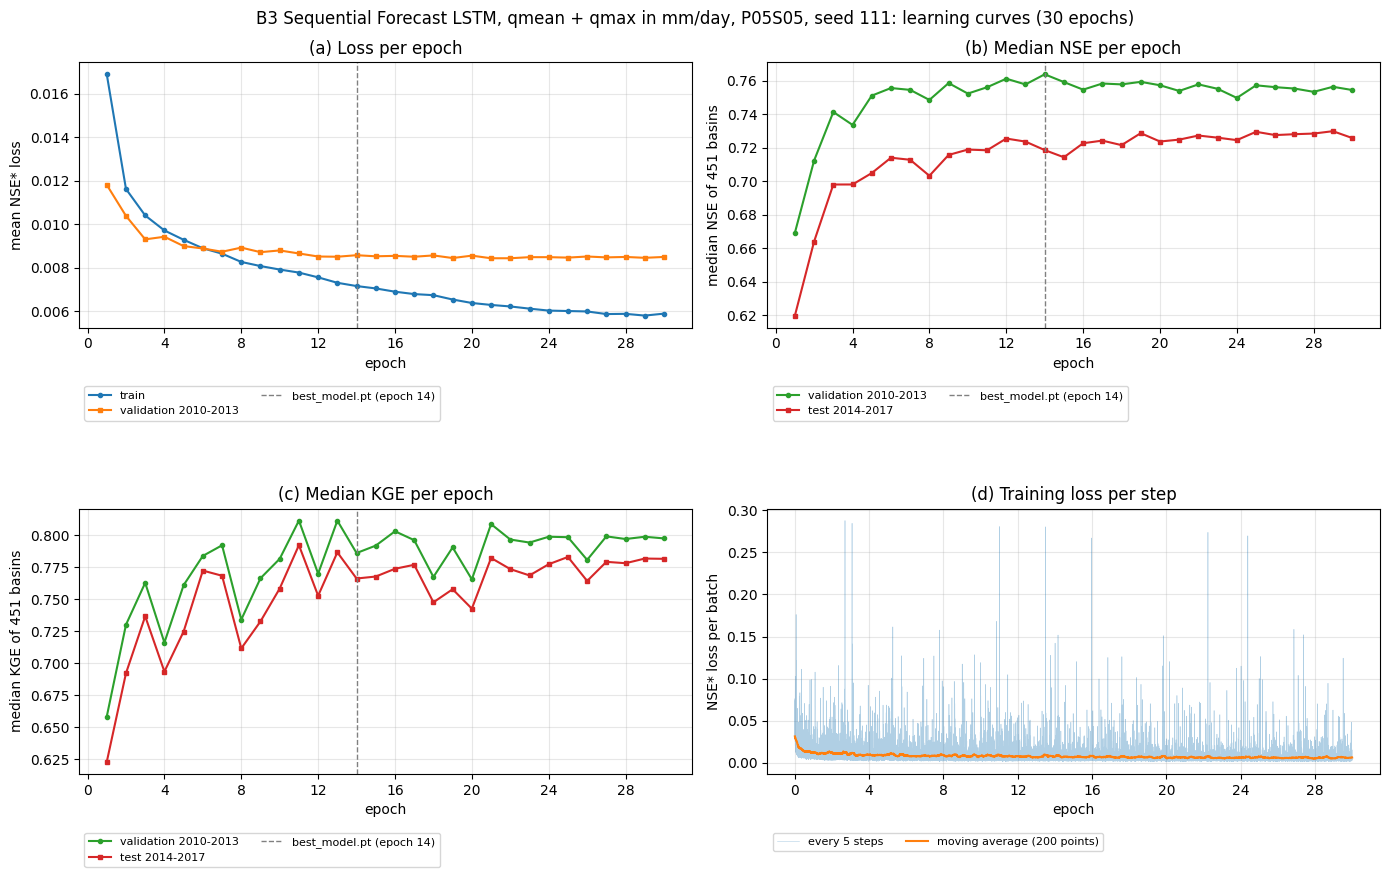

Hình: đường học của hạt giống 111 qua 30 epoch. (a) loss NSE* trung bình mỗi epoch của kỳ huấn luyện và kỳ validation; loss huấn luyện giảm trong khi loss validation tăng là dấu hiệu quá khớp. (b), (c) NSE và KGE trung vị 451 lưu vực của kỳ validation (dùng để chọn mô hình) và kỳ test (chỉ để theo dõi); vạch xám là epoch lưu thành best_model.pt (epoch 14: NSE validation 0,764, NSE test 0,719). (d) loss của từng lô 256 mẫu, ghi mỗi 5 bước (26070 điểm), đường cam là trung bình trượt 200 điểm; trục ngang đổi ra epoch (4345 bước/epoch).
Đã lưu /kaggle/working/b3_output/Figures/B3_Curve_B3_P05S05_SeqLSTM_Q_seed111.png
=> Đạt. Chạy Phần 8.


In [7]:
# Một hình 4 ô (chữ trong hình tiếng Anh, chú thích tiếng Việt in ngay dưới bằng caption):
#   (a) loss NSE* trung bình theo epoch của kỳ huấn luyện và validation (log Phần 5);
#   (b) NSE trung vị validation và test theo epoch (Phần 6), vạch epoch best_model.pt;
#   (c) KGE trung vị validation và test theo epoch (thư viện tính cùng NSE, metrics: [NSE, KGE]);
#   (d) loss huấn luyện theo bước đọc từ tệp sự kiện tensorboard trong thư mục run (thẻ train/total_loss, ghi mỗi
#       log_interval bước - logger.py dòng 105-127) kèm trung bình trượt, trục ngang đổi ra epoch.
# Kỳ validation, test lấy từ config; lưu b3_output/Figures/B3_Curve_<tên run>.png, tải về đặt ở
# Workspace/05_Training/08_B3_LamaHCEExt_Train/Figures/.
# Cần chạy Phần 1-6 trước trong phiên (dùng CURVE, SAVED_EPOCH, RUN_DIR, cfg_saved, period_label, EXP_NAME, RUN_SEED,
# OUT_DIR, basins).
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

STEP_TAG = "train/total_loss"


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


def vn(x, digits=3):
    # Số thập phân trong chú thích tiếng Việt dùng dấu phẩy.
    return f"{x:.{digits}f}".replace(".", ",")


# Loss theo bước từ tensorboard
ea = EventAccumulator(str(RUN_DIR), size_guidance={"scalars": 0})
ea.Reload()
steps = pd.DataFrame([(ev.step, ev.value) for ev in ea.Scalars(STEP_TAG)], columns=["step", "loss"]) \
    if STEP_TAG in ea.Tags()["scalars"] else pd.DataFrame(columns=["step", "loss"])
n_epochs = int(CURVE["epoch"].max())
steps_per_epoch = steps["step"].max() / n_epochs if len(steps) else np.nan
steps["epoch"] = steps["step"] / steps_per_epoch
window = int(min(200, max(5, len(steps) // 20)))           # điểm ghi (mỗi log_interval bước)
steps["trung bình trượt"] = steps["loss"].rolling(window, center=True, min_periods=1).mean()
steps.to_csv(OUT_DIR / f"steps_{EXP_NAME}.csv", index=False)

lab_val, lab_test = period_label(cfg_saved, "validation"), period_label(cfg_saved, "test")
FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ax = axes[0, 0]
ax.plot(CURVE["epoch"], CURVE["loss huấn luyện"], "o-", ms=3, label="train")
ax.plot(CURVE["epoch"], CURVE["loss validation"], "s-", ms=3, label=lab_val)
ax.set(xlabel="epoch", ylabel="mean NSE* loss", title="(a) Loss per epoch")
for ax, metric, title in [(axes[0, 1], "NSE", "(b) Median NSE per epoch"), (axes[1, 0], "KGE", "(c) Median KGE per epoch")]:
    ax.plot(CURVE["epoch"], CURVE[f"{metric} trung vị validation (tệp)"], "o-", ms=3, color="C2", label=lab_val)
    ax.plot(CURVE["epoch"], CURVE[f"{metric} trung vị test"], "s-", ms=3, color="C3", label=lab_test)
    ax.set(xlabel="epoch", ylabel=f"median {metric} of {len(basins)} basins", title=title)
ax = axes[1, 1]
ax.plot(steps["epoch"], steps["loss"], lw=0.4, alpha=0.35, color="C0", label=f"every {cfg_saved.log_interval} steps")
ax.plot(steps["epoch"], steps["trung bình trượt"], lw=1.5, color="C1", label=f"moving average ({window} points)")
ax.set(xlabel="epoch", ylabel="NSE* loss per batch", title="(d) Training loss per step")
for ax in axes.flat:
    if SAVED_EPOCH is not None and ax is not axes[1, 1]:
        ax.axvline(SAVED_EPOCH, color="grey", ls="--", lw=1, label=f"best_model.pt (epoch {SAVED_EPOCH})")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.20), ncol=2)
fig.suptitle(f"B3 Sequential Forecast LSTM, qmean + qmax in mm/day, {MASK_LEVEL}, seed {RUN_SEED}: learning curves ({n_epochs} epochs)")
fig.tight_layout(h_pad=4.0)
fig_path = FIG_DIR / f"B3_Curve_{EXP_NAME}.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
best = CURVE.set_index("epoch").loc[SAVED_EPOCH] if SAVED_EPOCH is not None else None
caption(f"đường học của hạt giống {RUN_SEED} qua {n_epochs} epoch. (a) loss NSE* trung bình mỗi epoch của kỳ huấn luyện "
        f"và kỳ validation; loss huấn luyện giảm trong khi loss validation tăng là dấu hiệu quá khớp. (b), (c) NSE và KGE "
        f"trung vị {len(basins)} lưu vực của kỳ validation (dùng để chọn mô hình) và kỳ test (chỉ để theo dõi); vạch xám là "
        f"epoch lưu thành best_model.pt"
        + (f" (epoch {SAVED_EPOCH}: NSE validation {vn(best['NSE trung vị validation (tệp)'])}, "
           f"NSE test {vn(best['NSE trung vị test'])})" if best is not None else "")
        + f". (d) loss của từng lô {cfg_saved.batch_size} mẫu, ghi mỗi {cfg_saved.log_interval} bước ({len(steps)} điểm), đường cam là "
        f"trung bình trượt {window} điểm; trục ngang đổi ra epoch ({steps_per_epoch:.0f} bước/epoch).")
print(f"Đã lưu {fig_path}")
print("=> Đạt. Chạy Phần 8." if len(steps) else "=> CHƯA có loss theo bước (không đọc được tệp tensorboard) - xem lại.")






## Phần 8 - Lưu nguồn B2/B1b, môi trường và manifest

In [8]:
# Manifest bao phủ cả config, trọng số, summary, curve, environment; không cần giữ cây Q tạm.
from importlib import metadata
ENV_LIBS=['neuralhydrology','torch','numpy','pandas','xarray','scipy','numba','ruamel.yaml','tensorboard']
installed=json.loads(metadata.distribution('neuralhydrology').read_text('direct_url.json'))['vcs_info']['commit_id']
if installed!=NH_COMMIT:
    raise ValueError('Commit thư viện thay đổi trong phiên.')
SUMMARY.update(step='B3',mask_level=MASK_LEVEL,nan_step_probability=P_STEP,nan_sequence_probability=P_SEQUENCE,
    ready_for_evaluation=EVALUATION_CHECKS_OK,B1b_source=B1_IDENTITY,B2_source=B2_IDENTITY,mask_preflight=B3_PREFLIGHT)
(OUT_DIR/f'summary_{EXP_NAME}.json').write_text(json.dumps(SUMMARY,ensure_ascii=False,indent=2),encoding='utf-8')
env={'seed':RUN_SEED,'experiment_name':EXP_NAME,'run_dir':RUN_DIR.relative_to(WORK_DIR).as_posix(),
    'notebook':f'08_B3_LamaHCEExt_Train_{MASK_LEVEL}_Seed{RUN_SEED}','step':'B3','python':sys.version.split()[0],
    'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu','neuralhydrology_commit':NH_COMMIT,
    'config_sha256':sha256(RUN_DIR/'config.yml'),'libs':{name:metadata.version(name) for name in ENV_LIBS},
    'protocol':{'epochs':cfg_saved.epochs,'early_stopping_patience':cfg_saved.early_stopping_patience,
        'data_on_gpu':cfg_saved.data_on_gpu,'test_every_epoch':True,'deterministic':False},
    'summary':SUMMARY,'q_inputs':Q_USE,'mask_level':MASK_LEVEL,
     'masking':{'nan_step_probability':P_STEP,'nan_sequence_probability':P_SEQUENCE,'training_only':True},
     'B2_source':B2_IDENTITY,'mask_preflight':B3_PREFLIGHT,'B1b_source':B1_IDENTITY,'T4_check_sha256':sha256(T4_REPORT_PATH),
    'q_dir_note':'Phần 3 dựng lại đúng quy trình B1b Version 1; hai cột Q mm/ngày; không đổi đơn vị lần hai.'}
(OUT_DIR/'environment.json').write_text(json.dumps(env,ensure_ascii=False,indent=2),encoding='utf-8')
files=sorted(p for directory in (RUN_DIR,OUT_DIR,CFG_DIR) for p in directory.rglob('*') if p.is_file() and p.name!='manifest.csv')
manifest=pd.DataFrame([{'file':p.relative_to(WORK_DIR).as_posix(),'bytes':p.stat().st_size,'sha256':sha256(p)} for p in files])
manifest.to_csv(OUT_DIR/'manifest.csv',index=False)
check_manifest(WORK_DIR,OUT_DIR/'manifest.csv',[RUN_DIR/'config.yml',OUT_DIR/'environment.json'])
if not Q_DIR.resolve().is_relative_to(WORK_DIR.resolve()) or Q_DIR.name!='LamaH_q_mmd_input':
    raise ValueError('Thư mục Q tạm ngoài working; không xóa.')
shutil.rmtree(Q_DIR)
show('Output B3 và hash',manifest.assign(sha256=manifest.sha256.str[:12]))
if not EVALUATION_CHECKS_OK:
    raise RuntimeError('Đã lưu log, trọng số và audit, nhưng kiểm checkpoint/evaluation chưa đạt; '
                       'không bàn giao run này cho Compare như kết quả hợp lệ.')
print('Hoàn tất B3 seed',RUN_SEED,'; Save Version rồi gắn đủ sáu Output vào 09_B3_LamaHCEExt_Compare.')


file,bytes,sha256
b3_configs/B3_P05S05_SeqLSTM_Q_seed111.yml,3918,43848965ca20
b3_output/B3_Q_normalization_check.csv,131,e6b9d398a432
b3_output/B3_config_delta.csv,74,53c82bfd42b1
b3_output/B3_mask_preflight.csv,261,fbb47388d187
b3_output/B3_train_dataset_check.csv,117,55def564fc7d
b3_output/Figures/B3_Curve_B3_P05S05_SeqLSTM_Q_seed111.png,288967,1d9e1dbf8136
b3_output/curve_B3_P05S05_SeqLSTM_Q_seed111.csv,5101,f204e70caae6
b3_output/environment.json,5020,c097418100fd
b3_output/evaluation_checks_B3_P05S05_SeqLSTM_Q_seed111.csv,877,daebc8642c14
b3_output/steps_B3_P05S05_SeqLSTM_Q_seed111.csv,1739491,e914c24b6f52


Hoàn tất B3 seed 111 ; Save Version rồi gắn đủ sáu Output vào 09_B3_LamaHCEExt_Compare.
